# Background Information

**Media condition comparison**

| Condition | Recipe difference | Carbon / amino-acid supply | Doubling time (min) | TF changes vs. basal |
|---|---|---|---:|---|
| Basal | `MIX0-57` (full volume) | 0.2% glucose; no amino-acid supplement | 44 | Reference condition; none listed |
| Acetate | `MIX0-58` | 0.4% acetate replaces glucose | 136 | Active: CRP (`CPLX0-226`) |
| Succinate | `MIX0-844` | 0.2% succinate replaces glucose | 82 | Active: CRP (`CPLX0-226`), DcuR (`PHOSPHO-DCUR`) |
| With amino acids (`with_aa`) | 80% `MIX0-57` + 20% 5× amino-acid supplement | Retains glucose and adds amino acids (final 1× supplement) | 25 | Active: TrpR, TyrR, ArgR, Lrp, MetJ; inactive: ArgP, PutA, LrhA |

All four use the same underlying mineral salts, gases, and trace metals. The carbon-source recipes differ in the supplied carbon compound; `with_aa` instead changes the basal recipe by adding the amino-acid mixture. The listed doubling times and TF changes are from `condition_defs.tsv`; TF changes are relative to basal.

**Gene-knockout function**

In [`gene_knockout.py`](../ecoli/variants/gene_knockout.py), `apply_variant` reads target IDs from `genes_to_knockout`. It accepts gene IDs (resolved from a cistron to its RNA/transcription-unit indices) or RNA/TU IDs directly, and handles one-item nested lists. It removes duplicate indices, then calls `sim_data.adjust_final_expression` with a zero factor for each matched TU, making this a complete expression knockout of the target gene's TU(s), rather than a DNA deletion. This updates the transcription expression and related regulation data in `sim_data`.

Unrecognized IDs and non-string entries are warned about and skipped; if nothing matches, `sim_data` is returned unchanged. The legacy `gene_knockout(sim_data, index)` entry point treats index 0 as control and maps other variant indices to an RNA entry, then applies the same zero-expression adjustment.

# Phase-1 Plan

**Goal:** study the data pattern / distribution of the gene-KO growth-rate time series (462 different single-cell KO with 2 seeds simulation) and compare 4 media: basal, acetate, succinate, amino acids (aa).\
The basal media simulation is set to a maximum of 12 generations; acetate, succinate, and aa are set to a maximum of 20 generations. These limits were chosen based on a previous generation-level deviation analysis.\
Some simulation are ended before pre-set maximum simulation and the resulting maximum simulation can be found in the summary file:
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_acetate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_basal_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_succinate_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_gene_knockout_462KO_with_aa_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_with_aa_seed1_2_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_wildtype_3media_seed100_101_all.csv
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_summary_errored_round1_all.csv
`. \
Proposed window based on generation-difference for each media:
`/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv`

**Data:** 
`/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet;
/user/home/il22158/work/vEcoli/reading/results/growth_rate/growth_rate_timeseries_errored_round1_all.parquet
`, one file per medium, concatenated with a `medium` column.

Wildtype (`baseline`) is included in each medium's pool and summaries. Black dots highlight wildtype in scatter plots; the red histogram line is the equally weighted mean of the valid wildtype seed means, before plot trimming. For the seed-agreement plots only, aa wildtype seeds 1 and 2 occupy the seed 100 and 101 axes respectively; exported seed IDs remain unchanged.

**Preliminary checks**
1. Inspect shape, dtypes, NaN/inf and time range per medium. *Reason:* files come from separate simulation runs; differing lengths or missing values would bias every comparison.
2. Choose the unit of analysis: the 2 seeds of one knockout are replicates, so aggregate to one value per (medium, gene KO) before testing. *Reason:* pooling all rows treats correlated observations as independent and makes p-values far too small.

**Step 1. Per-KO summary and variability**

Preprocessing
- Restrict the time-series rows with proposed windows for each media (/user/home/il22158/work/vEcoli/job/tdi_summary_40trial_5media_composite_tdi.csv). A run is valid if it has more than one distinct nonzero output time point; separately record whether it reached the target generation.
- Return run-validity and division-outcome counts, plus the maximum generation reached for each medium/KO/seed. Do not label a run that misses the target generation as a failed simulation; it is a valid run with division target not reached.
- Coversion: from 1/s to 1/h.
- For valid runs that do not reach the window end, use available observations within the window; do not impute zero. Runs without window observations have no window mean. Invalid runs (one or zero distinct nonzero output time points) are excluded from KO means.

Plotting
- For the per-KO distribution, average the available seed means within each KO and medium. A KO is "common" when it has a non-missing per-KO mean in all four media; this does not require both seeds or completion to the maximum generation. The plotted distributions and summary table use the same common-KO set (n=? in the current output).
- The seed-to-seed scatter uses a separate inclusion rule: a KO is plotted for a medium when one seed means are present, each calculated from that seed's available time points within generations window. It does not require either seed to reach the maximum generation. The legend's n is this per-medium count of KOs with both seed means (? aa, ? acetate, ? basal, and ? succinate in the current output); it is not the common-KO count.
- Show the per-KO distribution with a box plot and overlaid points, plus the seed-1 versus seed-2 scatter plot with a 1:1 reference line. Report the common-KO count, median, and IQR.

**Step 2. Distribution plots** (histogram + KDE, violin)
- *Principle:* the histogram (shaded) with a KDE line estimates the probability density; the violin/box plot shows quartiles, outliers and density shape.
- *Reason:* KDE/violin reveal multimodality. Use `common_norm=False` so each medium is normalised on its own.

**Step 3. Temporal pattern**
- Plot mean +/- IQR growth rate vs time per medium; normalise time to 0-1 if cell cycle length differs.
- *Principle:* aggregate over seeds and knockouts at each time point.
- *Reason:* the data are time series, so media may differ in dynamics (initial transient, steady state, variability over time), not only overall distribution. Median/IQR are robust to outlier simulations.

**Expected output:** compact per-KO summary and plots, test and effect-size table, time-course plot, cross-medium correlation matrix, and a short interpretation of how the 4 media differ./
Output directory: `/user/home/il22158/work/vEcoli/reading/results/pattern`

# Phase-1 Code

In [1]:
# step0 - part 1: inventory of observed KO labels and baseline runs, save combined data 

import pandas as pd, numpy as np

base = "/user/home/il22158/work/vEcoli/reading/results/growth_rate/"
files = {
    "basal":     "growth_rate_timeseries_gene_knockout_462KO_basal_all.parquet",
    "acetate":   "growth_rate_timeseries_gene_knockout_462KO_acetate_all.parquet",
    "succinate": "growth_rate_timeseries_gene_knockout_462KO_succinate_all.parquet",
    "aa":        "growth_rate_timeseries_gene_knockout_462KO_with_aa_all.parquet",
    "errored":    "growth_rate_timeseries_errored_round1_all.parquet"
}
priorities=["errored", "errored_no_overlap" ] 
# The errored parquet will be kept for same seed/media; and within that, the errored_no_overlap will be considered next
drop={"media": "with_aa", "seed": 101} 
# The 101 seed always have an chromosome error in with_aa

summary_files = {m: base + f.replace("timeseries", "summary").replace(".parquet", ".csv")
                 for m, f in files.items()}

GENE = "label"                 # e.g. "KO: EG10001"
SEED = "lineage_seed"
GEN  = "generation"
TIME = "time"
VAL  = "listeners__mass__instantaneous_growth_rate"
MASS = "listeners__mass__dry_mass"
MAX_GENERATION = {"basal": 12, "aa": 20, "acetate": 20, "succinate": 20}

dfs = {m: pd.read_parquet(base + f) for m, f in files.items()}
ko_summaries = {m: pd.read_csv(p) for m, p in summary_files.items()}
reruns = dfs.pop(priorities[0])
rerun_summary = ko_summaries.pop(priorities[0])
medium_pattern = r"_(acetate|succinate|with_aa)(?:_|$)"
for data in (reruns, rerun_summary):
    data["medium"] = data["project"].str.extract(medium_pattern, expand=False).replace({"with_aa": "aa"})
    if data["medium"].isna().any():
        raise ValueError(f"Unrecognized rerun projects: {data.loc[data['medium'].isna(), 'project'].unique()}")

# Select whole runs: rerun file first, then its errored_no_overlap projects.
source_keys = ["project", "variant", GENE, SEED, "_rerun"]
for m in dfs:
    records = pd.concat([dfs[m].assign(_rerun=False),
                         reruns.loc[reruns["medium"] == m].drop(columns="medium").assign(_rerun=True)], ignore_index=True)
    summaries = pd.concat([ko_summaries[m].assign(_rerun=False),
                           rerun_summary.loc[rerun_summary["medium"] == m].drop(columns="medium").assign(_rerun=True)], ignore_index=True)
    if m == {"with_aa": "aa"}.get(drop["media"], drop["media"]):
        records = records.loc[records[SEED] != drop["seed"]]
        summaries = summaries.loc[summaries[SEED] != drop["seed"]]
    if records[source_keys].isna().any().any() or summaries[source_keys].isna().any().any():
        raise ValueError(f"Missing run identifiers in {m}")
    if summaries.duplicated(source_keys).any():
        raise ValueError(f"Duplicate source run identifiers in {m} summary")
    candidates = pd.concat([records[source_keys], summaries[source_keys]], ignore_index=True).drop_duplicates()
    candidates["_no_overlap"] = candidates["_rerun"] & candidates["project"].str.endswith("_" + priorities[1])
    if candidates.duplicated([GENE, SEED, "_rerun", "_no_overlap"]).any():
        raise ValueError(f"Multiple runs with the same priority in {m}")
    selected = (candidates.sort_values(["_rerun", "_no_overlap"], ascending=False)
                .drop_duplicates([GENE, SEED]))
    dfs[m] = records.merge(selected[source_keys], on=source_keys, validate="many_to_one").drop(columns="_rerun")
    ko_summaries[m] = summaries.merge(selected[source_keys], on=source_keys, validate="one_to_one").drop(columns="_rerun")
    print(f"{m}: selected {len(selected)} KO/seed runs; removed {len(candidates) - len(selected)} lower-priority runs")
    
# Add wildtype data to the knockout datasets for each medium
WILDTYPE = "baseline"
wildtype_files = [
    "growth_rate_timeseries_wildtype_3media_seed100_101_all.parquet",
    "growth_rate_timeseries_wildtype_with_aa_seed1_2_all.parquet",
]
wildtype_projects = {
    "wildtype_basal": "basal", "wildtype_acetate": "acetate",
    "wildtype_succinate": "succinate", "wildtype_with_aa_s1-5": "aa",
}
wt = pd.concat([pd.read_parquet(base + f) for f in wildtype_files], ignore_index=True)
if set(wt["project"]) != set(wildtype_projects) or set(wt[GENE]) != {WILDTYPE}:
    raise ValueError("Unexpected wildtype projects or labels")
wt["medium"] = wt["project"].map(wildtype_projects)
for m in dfs:
    if WILDTYPE in set(dfs[m][GENE]):
        raise ValueError(f"Wildtype label already present in {m} knockout data")
    w = wt[wt["medium"] == m].drop(columns="medium")
    expected_seeds = {1, 2} if m == "aa" else {100, 101}
    if set(w[SEED]) != expected_seeds:
        raise ValueError(f"Unexpected wildtype seeds in {m}: {sorted(w[SEED].unique())}")
    dfs[m] = pd.concat([dfs[m], w], ignore_index=True)

def seed_plot_values(per_seed):
    has_seed_2 = per_seed[SEED].eq(2).groupby([per_seed["medium"], per_seed[GENE]]).transform("any")
    aa_pair = per_seed[SEED].isin([1, 2]) | (per_seed[SEED].eq(100) & ~has_seed_2)
    plot_values = per_seed.loc[(per_seed["medium"] != "aa") | aa_pair].copy()
    aa = plot_values["medium"] == "aa"
    plot_values.loc[aa, SEED] = plot_values.loc[aa, SEED].map({1: 100, 2: 101, 100: 101})
    return plot_values

# Summary files (one row per project, variant, and seed)
for m, s in ko_summaries.items():
    print(f"\n{m} summary:", s.shape)
    print(s.head(3))
wt_summaries = []
for f in wildtype_files:
    s = pd.read_csv(base + f.replace("timeseries", "summary").replace(".parquet", ".csv"))
    wt_summaries.append(s)
    print(f"\n{f} summary:")
    print(s)
wt_summary = pd.concat(wt_summaries, ignore_index=True)

# Inventory observed KO labels in the combined data, without filtering by validity.
def create_inventory_table(dfs, wt_summary, wildtype_projects):
    from IPython.display import display
    inventory_rows = []
    for m, d in dfs.items():
        ko = d.loc[d[GENE] != WILDTYPE]
        if ko[GENE].isna().any():
            raise ValueError(f"Missing KO labels in {m}")
        ko_count = ko[GENE].nunique()
        ko_runs = ko[[GENE, SEED]].drop_duplicates().shape[0]
        seeds_per_ko = ko.groupby(GENE)[SEED].nunique()
        baseline_runs = d.loc[d[GENE] == WILDTYPE, [GENE, SEED]].drop_duplicates().shape[0]
        baseline_summary = wt_summary.loc[wt_summary["project"].map(wildtype_projects) == m]
        if not baseline_summary[GENE].eq(WILDTYPE).all() or baseline_summary.duplicated(["project", "variant", SEED]).any():
            raise ValueError(f"Unexpected or duplicate baseline summary runs in {m}")
        inventory_rows.append({
            "medium": m,
            "observed KO labels": ko_count,
            "observed KO/seed pairs": ko_runs,
            "KOs with 1 seed": seeds_per_ko.eq(1).sum(),
            "KOs with 2 seeds": seeds_per_ko.eq(2).sum(),
            "KOs with 3+ seeds": seeds_per_ko.ge(3).sum(),
            "baseline runs in summary": len(baseline_summary),
            "observed total including baseline": ko_runs + baseline_runs,
        })
    inventory_table = pd.DataFrame(inventory_rows).set_index("medium")
    print("Observed KO labels in the combined time-series data, regardless of run validity:")
    display(inventory_table)
    return inventory_table

inventory_raw = create_inventory_table(dfs, wt_summary, wildtype_projects)

# Investigate KOs with more than two observed seeds.
from IPython.display import display
observed_runs = pd.concat([d.assign(medium=m) for m, d in dfs.items()], ignore_index=True)
observed_runs = (observed_runs.loc[observed_runs[GENE] != WILDTYPE]
                 .groupby(["medium", GENE, SEED, "project", "variant"], as_index=False)
                 .agg(n_rows=(TIME, "size"), max_generation=(GEN, "max")))
seed_counts = observed_runs.groupby(["medium", GENE])[SEED].transform("nunique")
print("Observed runs for KOs with more than two seeds:")
display(observed_runs.loc[seed_counts > 2].sort_values(["medium", GENE, SEED]))

# Remove the specified AA G7579 seed-100 run from both data and summary.
for data_by_medium in (dfs, ko_summaries):
    aa = data_by_medium["aa"]
    remove = aa[GENE].eq("KO: G7579") & aa[SEED].eq(100)
    if not remove.any():
        raise ValueError("AA KO: G7579 seed 100 not found")
    data_by_medium["aa"] = aa.loc[~remove].copy()

# Rerun inventory after deletion
inventory_final = create_inventory_table(dfs, wt_summary, wildtype_projects)

basal: selected 924 KO/seed runs; removed 0 lower-priority runs
acetate: selected 924 KO/seed runs; removed 3 lower-priority runs
succinate: selected 924 KO/seed runs; removed 2 lower-priority runs
aa: selected 925 KO/seed runs; removed 74 lower-priority runs

basal summary: (924, 15)
                                  project  variant        label  lineage_seed  \
0  gene_knockout_462KO_basal_operon_on_p1        1  KO: EG10001           100   
1  gene_knockout_462KO_basal_operon_on_p1        1  KO: EG10001           101   
2  gene_knockout_462KO_basal_operon_on_p1        2  KO: EG10004           100   

   mean_growth_rate  median_growth_rate  std_growth_rate  max_growth_rate  \
0          0.000199            0.000206         0.000040         0.000301   
1          0.000211            0.000212         0.000044         0.000593   
2          0.000194            0.000199         0.000038         0.000316   

   initial_dry_mass  final_dry_mass  max_dry_mass  fold_change_mass  \
0        

,observed KO labels,observed KO/seed pairs,KOs with 1 seed,KOs with 2 seeds,KOs with 3+ seeds,baseline runs in summary,observed total including baseline
medium,,,,,,,
basal,462,924,0,462,0,2,926
acetate,462,924,0,462,0,2,926
succinate,462,924,0,462,0,2,926
aa,462,925,0,461,1,2,927


Observed runs for KOs with more than two seeds:


,medium,label,lineage_seed,project,variant,n_rows,max_generation
868,aa,KO: G7579,1,gene_knockout_G7579_with_aa_errored_no_overlap,1,1045,20
869,aa,KO: G7579,2,gene_knockout_G7579_with_aa_errored_no_overlap,1,1219,20
870,aa,KO: G7579,100,gene_knockout_G7579_with_aa,1,36,1


Observed KO labels in the combined time-series data, regardless of run validity:


,observed KO labels,observed KO/seed pairs,KOs with 1 seed,KOs with 2 seeds,KOs with 3+ seeds,baseline runs in summary,observed total including baseline
medium,,,,,,,
basal,462,924,0,462,0,2,926
acetate,462,924,0,462,0,2,926
succinate,462,924,0,462,0,2,926
aa,462,924,0,462,0,2,926


In [2]:
# Save the raw inventory and combined data to the output directory.
from pathlib import Path
OUT0 = Path(base).parent / "pattern"
OUT0.mkdir(parents=True, exist_ok=True)
inventory_final.to_csv(OUT0 / "step0_data_inventory.csv")
# combined = pd.concat(
#     [data.assign(medium=medium) for medium, data in dfs.items()],
#     ignore_index=True,
# )
# combined.to_parquet(OUT0 / "step0_combined.parquet", index=False)

In [8]:
## Prepare data for later computing
# Combine the finalized per-medium data; preserve this unfiltered version.
raw = pd.concat(
    [frame.assign(medium=medium) for medium, frame in dfs.items()],
    ignore_index=True,
)

# Keep finite growth rates at positive timepoints for downstream analysis.
pf = raw.loc[
    np.isfinite(raw[VAL]) & raw[TIME].gt(0)
].copy()

# Compatibility with later cells that refer to df.
df = pf

medium                             basal        acetate      succinate  \
n_rows                     426707.000000  583278.000000  668772.000000   
n_gene                        463.000000     463.000000     463.000000   
n_variant                      94.000000       2.000000       2.000000   
n_seed                          2.000000       2.000000       2.000000   
configured_max_generation      12.000000      20.000000      20.000000   
max_generation_observed        12.000000      20.000000      20.000000   
n_nan                           0.000000       0.000000       0.000000   
n_inf                           0.000000       0.000000       0.000000   
n_neg                         183.000000      58.000000       7.000000   
n_zero                       7910.000000    9422.000000   11439.000000   
t_min                           0.000000       0.000000       0.000000   
t_max                       66940.000000   78859.000000   90878.000000   
gr_min                         -0.0022


Run validity among runs with extracted rows (>1 distinct nonzero output time point):
                    valid_runs  extracted_runs
medium    run_type                            
aa        KO               812             924
          baseline           2               2
acetate   KO               812             924
          baseline           2               2
basal     KO               812             924
          baseline           2               2
succinate KO               812             924
          baseline           2               2

Generation outcome, reported separately from run validity:
division_outcome  did_not_reach_target_generation  reached_target_generation
medium                                                                      
aa                                            371                        555
acetate                                       526                        400
basal                                         318                        608

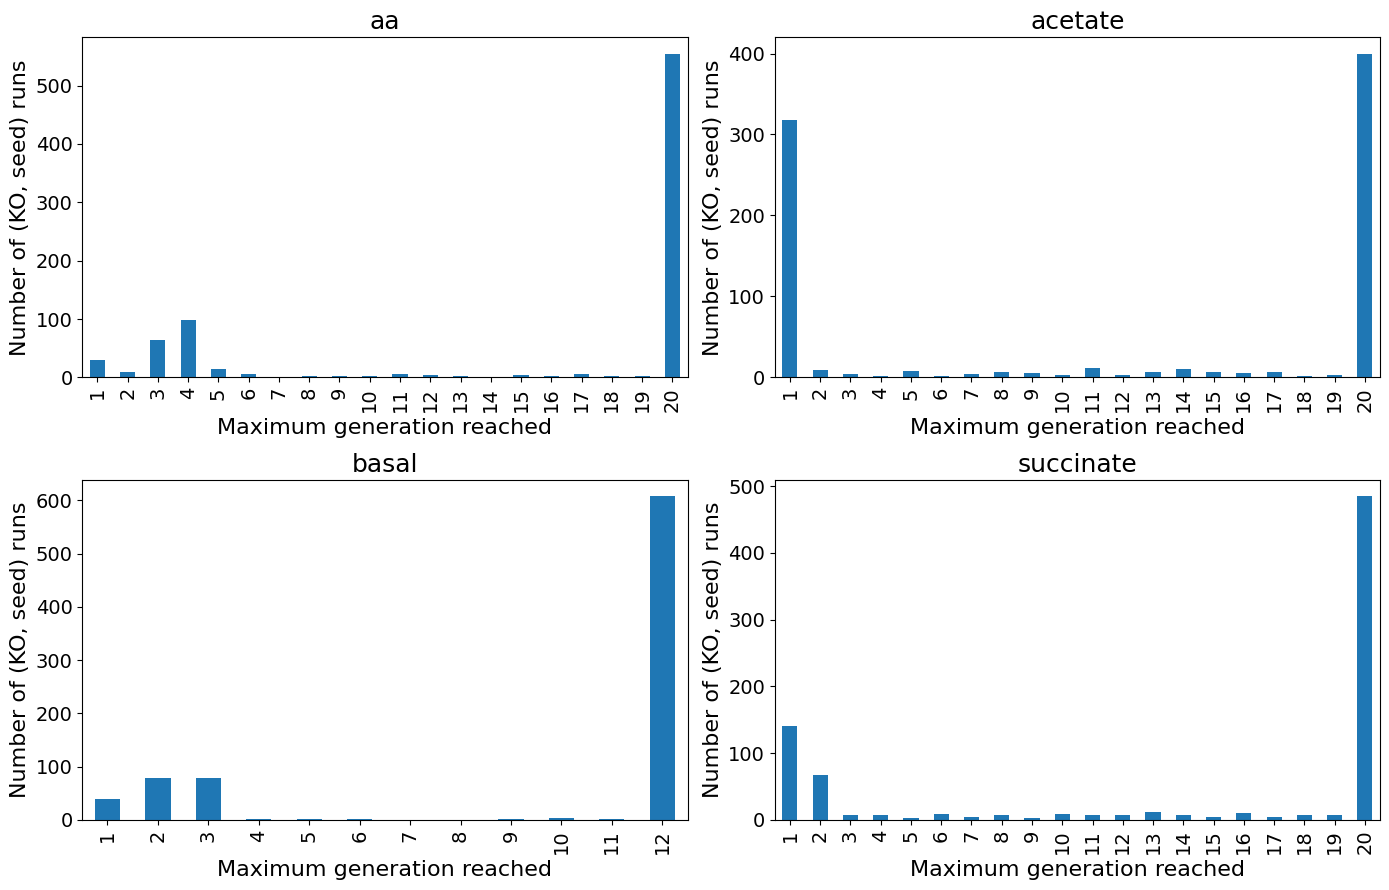

In [9]:
# Step0 - part2: details check for loaded data; save and run status

# Check 1: shape, dtypes, NaN/inf, time range per medium
rows = []
for m, d in dfs.items():
    v = d[VAL]
    rows.append({
        "medium": m,
        "n_rows": len(d),
        "n_gene": d[GENE].nunique(),
        "n_variant": d["variant"].nunique(),
        "n_seed": d[SEED].nunique(),
        "configured_max_generation": MAX_GENERATION[m],
        "max_generation_observed": d[GEN].max(),
        "n_nan": v.isna().sum(),
        "n_inf": np.isinf(v).sum(),
        "n_neg": (v < 0).sum(),
        "n_zero": (v == 0).sum(),   # includes the t=0 rows of each generation
        "t_min": d[TIME].min(),
        "t_max": d[TIME].max(),
        "gr_min": v.min(),
        "gr_median": v.median(),
        "gr_max": v.max(),
    })
print(pd.DataFrame(rows).set_index("medium").T)
run_sources = raw[["medium", GENE, SEED, "project", "variant"]].drop_duplicates()
duplicate_runs = run_sources.groupby(["medium", GENE, SEED]).size()
if (duplicate_runs > 1).any():
    import warnings
    warnings.warn(f"{(duplicate_runs > 1).sum()} KO/seed/medium combinations have multiple runs; "
                  "downstream run statistics pool them. KO summaries contain original runs only.")

raw["_t"] = raw[TIME].where((raw[TIME] > 0) & np.isfinite(raw[VAL]))  # NaN -> not counted as output
sim_status = (raw.groupby(["medium", GENE, SEED])
                .agg(n_output_timepoints=("_t", "nunique"), max_gen=(GEN, "max"))
                .reset_index())
sim_status["valid_run"] = sim_status["n_output_timepoints"] > 1
sim_status["target_max_gen"] = sim_status["medium"].map(MAX_GENERATION)
sim_status["reached_target_generation"] = sim_status["max_gen"] >= sim_status["target_max_gen"]
sim_status["division_outcome"] = np.where(
    sim_status["reached_target_generation"], "reached_target_generation", "did_not_reach_target_generation"
)
sim_status["run_status"] = np.where(sim_status["valid_run"], "valid_run", "invalid_run")
print("\nRun validity among runs with extracted rows (>1 distinct nonzero output time point):")
print(sim_status.assign(run_type=np.where(sim_status[GENE] == WILDTYPE, "baseline", "KO"))
      .groupby(["medium", "run_type"])["valid_run"].agg(valid_runs="sum", extracted_runs="size"))
print("\nGeneration outcome, reported separately from run validity:")
print(pd.crosstab(sim_status["medium"], sim_status["division_outcome"]))

# Generations actually reached per (knockout, seed)
for m, d in dfs.items():
    g = d.groupby([GENE, SEED])[GEN].max()
    print(f"\n{m}: max generation reached per (KO, seed)")
    print(g.value_counts().sort_index())

# Check 2: average over valid seeds, then one value per (medium, gene KO).
per_seed = (df.groupby(["medium", GENE, SEED])
              .agg(mean=(VAL, "mean"), n_output_timepoints=(TIME, "nunique")).reset_index())
per_seed["valid_run"] = per_seed["n_output_timepoints"] > 1
per_ko = (per_seed[per_seed["valid_run"]]
          .groupby(["medium", GENE])["mean"].mean().reset_index())

print(per_ko.groupby("medium")[GENE].nunique())
wide = per_ko.pivot(index=GENE, columns="medium", values="mean")
print("KOs missing per medium:\n", wide.isna().sum())
print(wide.describe())

# Visualization - Accumulated bar plot for distribution of maximum generation reached per (KO, seed) across media
import os, matplotlib.pyplot as plt
OUT0 = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT0, exist_ok=True)
gen_counts = sim_status[sim_status["valid_run"]].pivot_table(index="max_gen", columns="medium", values=SEED, aggfunc="size", fill_value=0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, gen_counts.columns):
    c = gen_counts[m].reindex(range(1, 13), fill_value=0) if m == "basal" else gen_counts[m]
    c.plot(kind="bar", ax=ax)
    ax.set_title(m, fontsize=18); ax.set_xlabel("Maximum generation reached", fontsize=16)
    ax.set_ylabel("Number of (KO, seed) runs", fontsize=16); ax.tick_params(labelsize=14)
plt.tight_layout(); plt.savefig(f"{OUT0}/step0_max_generation_stacked_bar.png", dpi=150); plt.show()

# File save - save the invalid/valid runs per KO, seed, media
sim_status.to_csv(f"{OUT0}/step0_run_status_per_KO_seed_media.csv", index=False)

Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                814           112                    555   
acetate           814           112                    400   
basal             814           112                    608   
succinate         814           112                    485   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                        259         926             0.87905  
acetate                   414         926             0.87905  
basal                     206         926             0.87905  
succinate                 329         926             0.87905  

Growth rate for 407 common KOs and wildtype (when present):
           count    median       IQR
medium                              
basal      407.0  0.7871

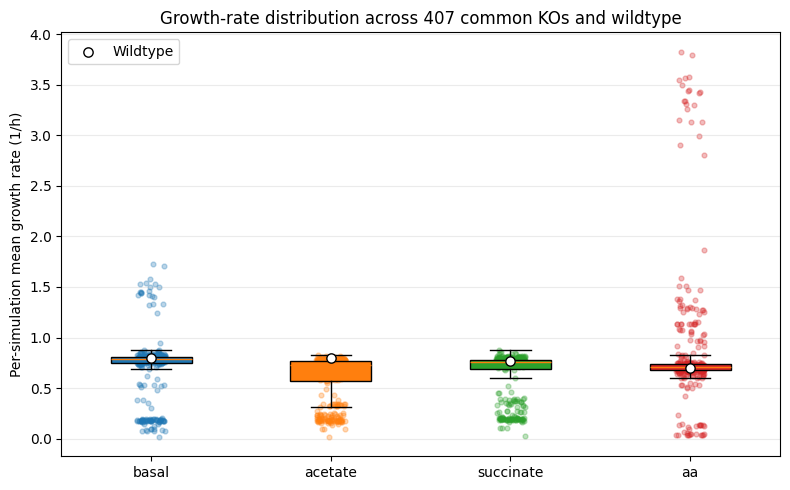

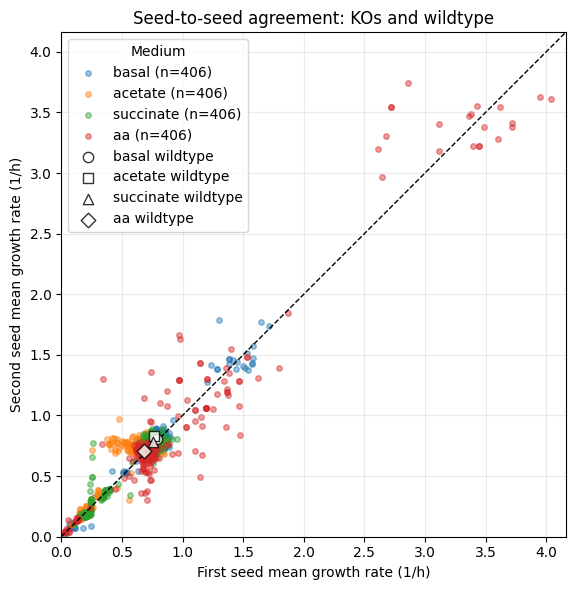

In [10]:
# Step 1a: per-KO growth patterns and seed agreement using all timepoints
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

medium_order = ["basal", "acetate", "succinate", "aa"]

# df contains finite growth-rate values at nonzero timepoints.
# Convert growth rate from 1/s to 1/h.
d = df.copy()
d[VAL] = d[VAL] * 3600

run_mean = (
    d.groupby(["medium", GENE, SEED])
     .agg(
         run_mean=(VAL, "mean"),
         n_run_points=(TIME, "nunique"),
     )
     .reset_index()
)

# Run validity is independent of whether the target generation was reached.
run_info = sim_status[
    ["medium", GENE, SEED, "n_output_timepoints", "max_gen"]
].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = (
    run_info["max_gen"] >= run_info["target_max_gen"]
)
run_info["division_success"] = (
    run_info["valid_run"] & run_info["reached_target_generation"]
)

ps = run_info.merge(
    run_mean,
    on=["medium", GENE, SEED],
    how="left",
)
ps["n_run_points"] = ps["n_run_points"].fillna(0).astype(int)

missing_mean = ps["valid_run"] & ps["run_mean"].isna()
if missing_mean.any():
    raise ValueError("A valid simulation has no growth-rate data")

ps["mean"] = ps["run_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1a_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = (
    ps["valid_run"] & ~ps["reached_target_generation"]
)
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = (
    outcomes["valid_runs"] / outcomes["total_runs"]
)
outcomes.to_csv(f"{OUT}/step1a_simulation_outcomes.csv")

print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()

ko_status["n_invalid_seeds"] = (
    ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
)
ko_status["n_valid_seeds_below_target"] = (
    ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
)
ko_status["status"] = np.select(
    [
        ko_status["n_valid_seeds"] == 0,
        ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
        ko_status["n_division_successes"] == 0,
    ],
    [
        "no_valid_run",
        "all_seeds_reached_target",
        "no_seed_reached_target",
    ],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1a_per_KO_simulation_status.csv", index=False)

# Average available valid-seed means within each KO and medium.
ko = (
    ps.groupby(["medium", GENE])["mean"]
      .mean()
      .reset_index()
)
ko.to_csv(f"{OUT}/step1a_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1a_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1a_per_KO_summary.csv")

print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)
for i, (patch, medium) in enumerate(
    zip(box["boxes"], medium_order),
    start=1,
):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(
        i + jitter,
        common[medium],
        color=colors[i - 1],
        s=12,
        alpha=0.3,
    )
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)

ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(
    index=["medium", GENE],
    columns=SEED,
    values="mean",
)
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")

seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))

for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has valid means for both seeds, so it is not plotted")
        continue

    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(
        pair[seed_columns[0]],
        pair[seed_columns[1]],
        color=colors[i],
        s=16,
        alpha=0.45,
        label=f"{medium} (n={len(pair)})",
    )

for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, alpha = 0.8,
                   facecolor="white", edgecolor="black", s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)

ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(low, high),
    ylim=(low, high),
    xlabel="First seed mean growth rate (1/h)",
    ylabel="Second seed mean growth rate (1/h)",
    title="Seed-to-seed agreement: KOs and wildtype",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1a_seed_agreement.png", dpi=180)
plt.show()

Simulation validity (>1 distinct nonzero output time point) and generation outcome:
           valid_runs  invalid_runs  valid_reaching_target  \
medium                                                       
aa                598           328                    555   
acetate           487           439                    400   
basal             617           309                    608   
succinate         598           328                    485   

           valid_below_target  total_runs  valid_run_fraction  
medium                                                         
aa                         43         926            0.645788  
acetate                    87         926            0.525918  
basal                       9         926            0.666307  
succinate                 113         926            0.645788  

Growth rate for 293 common KOs and wildtype (when present):
           count    median       IQR
medium                              
basal      293.0  0.7766

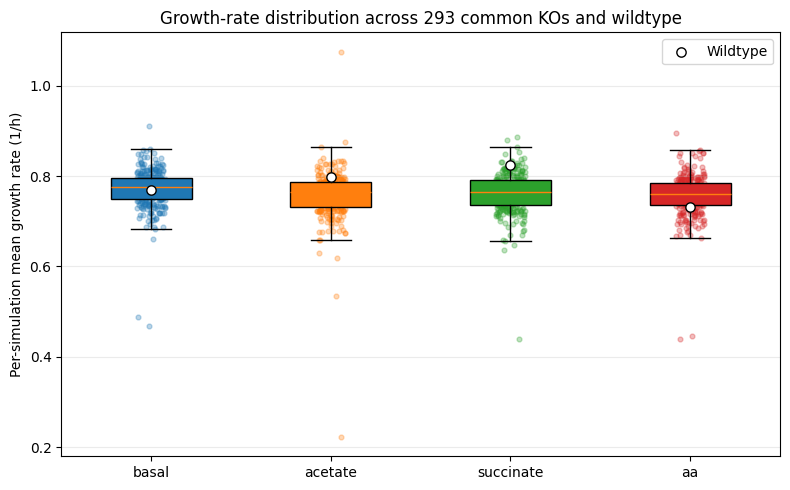

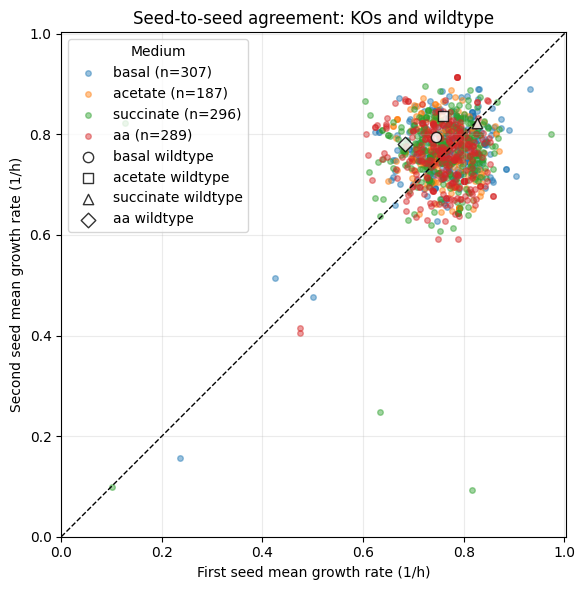

In [14]:
# Step 1b: per-KO growth patterns and seed agreement (growth rate in 1/h) with selected windows
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

OUT = "/user/home/il22158/work/vEcoli/reading/results/pattern"
os.makedirs(OUT, exist_ok=True)

medium_order = ["basal", "acetate", "succinate", "aa"]

# df contains finite growth-rate values at nonzero timepoints.
# Convert growth rate from 1/s to 1/h.
d = df.copy()
d[VAL] = d[VAL] * 3600

WINDOWS_FILE = "/user/home/il22158/work/vEcoli/reading/results/tdi/tdi_summary_462KO_4media_composite_tdi.csv"
WINDOW_MEDIA = {"basal": "basal", "with_aa": "aa", "acetate": "acetate", "succinate": "succinate"}
medium_order = ["basal", "acetate", "succinate", "aa"]

window_table = pd.read_csv(WINDOWS_FILE)
window_table = window_table[window_table["Media"].isin(WINDOW_MEDIA)]
window_table["medium"] = window_table["Media"].map(WINDOW_MEDIA)
if window_table["medium"].isna().any():
    raise ValueError("TDI window file contains a medium not used in this analysis")
window_bounds = {}
for _, row in window_table.iterrows():
    start, end = map(int, row["Proposed generation window"].split("-"))
    window_bounds[row["medium"]] = (start, end)
if set(window_bounds) != set(medium_order):
    raise ValueError(f"Expected TDI windows for {medium_order}, found {sorted(window_bounds)}")
window_bounds["basal"] = (4, 11) # Manual set for basal medium

# Load data with window_bounds...
GENERATION_COL = "generation"  # Replace with the actual generation column in df.
d["_window_start"] = d["medium"].map(
    {medium: bounds[0] for medium, bounds in window_bounds.items()}
)
d["_window_end"] = d["medium"].map(
    {medium: bounds[1] for medium, bounds in window_bounds.items()}
)
d = d[
    d[GENERATION_COL].between(d["_window_start"], d["_window_end"])
].copy()

run_mean = (
    d.groupby(["medium", GENE, SEED])
     .agg(
         run_mean=(VAL, "mean"),
         n_run_points=(TIME, "nunique"),
     )
     .reset_index()
)
# Run validity is independent of whether the target generation was reached.
run_info = sim_status[
    ["medium", GENE, SEED, "n_output_timepoints", "max_gen"]
].copy()
run_info["valid_run"] = run_info["n_output_timepoints"] > 1
run_info["target_max_gen"] = run_info["medium"].map(MAX_GENERATION)
run_info["reached_target_generation"] = (
    run_info["max_gen"] >= run_info["target_max_gen"]
)
run_info["division_success"] = (
    run_info["valid_run"] & run_info["reached_target_generation"]
)

ps = run_info.merge(
    run_mean,
    on=["medium", GENE, SEED],
    how="left",
)
ps["n_run_points"] = ps["n_run_points"].fillna(0).astype(int)
ps["valid_run"] = ps["n_run_points"] > 1
ps["division_success"] = ps["valid_run"] & ps["reached_target_generation"]

missing_mean = ps["valid_run"] & ps["run_mean"].isna()
if missing_mean.any():
    raise ValueError("A valid simulation has no growth-rate data")

ps["mean"] = ps["run_mean"].where(ps["valid_run"])
ps["status"] = np.select(
    [~ps["valid_run"], ~ps["reached_target_generation"]],
    ["invalid_run", "did_not_reach_target_generation"],
    default="reached_target_generation",
)
ps.to_csv(f"{OUT}/step1_per_seed_values.csv", index=False)

ps["valid_but_below_target"] = (
    ps["valid_run"] & ~ps["reached_target_generation"]
)
outcomes = ps.groupby("medium").agg(
    valid_runs=("valid_run", "sum"),
    invalid_runs=("valid_run", lambda x: (~x).sum()),
    valid_reaching_target=("division_success", "sum"),
    valid_below_target=("valid_but_below_target", "sum"),
    total_runs=("valid_run", "size"),
)
outcomes["valid_run_fraction"] = (
    outcomes["valid_runs"] / outcomes["total_runs"]
)
outcomes.to_csv(f"{OUT}/step1_simulation_outcomes.csv")

print("Simulation validity (>1 distinct nonzero output time point) and generation outcome:")
print(outcomes)

ko_status = ps.groupby(["medium", GENE]).agg(
    n_seed_outputs=(SEED, "nunique"),
    n_valid_seeds=("valid_run", "sum"),
    n_division_successes=("division_success", "sum"),
    max_generation_reached=("max_gen", "max"),
    target_max_generation=("target_max_gen", "first"),
).reset_index()

ko_status["n_invalid_seeds"] = (
    ko_status["n_seed_outputs"] - ko_status["n_valid_seeds"]
)
ko_status["n_valid_seeds_below_target"] = (
    ko_status["n_valid_seeds"] - ko_status["n_division_successes"]
)
ko_status["status"] = np.select(
    [
        ko_status["n_valid_seeds"] == 0,
        ko_status["n_division_successes"] == ko_status["n_seed_outputs"],
        ko_status["n_division_successes"] == 0,
    ],
    [
        "no_valid_run",
        "all_seeds_reached_target",
        "no_seed_reached_target",
    ],
    default="mixed_outcome",
)
ko_status.to_csv(f"{OUT}/step1_per_KO_simulation_status.csv", index=False)

# Average available valid-seed means within each KO and medium.
ko = (
    ps.groupby(["medium", GENE])["mean"]
      .mean()
      .reset_index()
)
ko.to_csv(f"{OUT}/step1_per_KO_values.csv", index=False)

wide = ko.pivot(index=GENE, columns="medium", values="mean")
common = wide.reindex(columns=medium_order).dropna()
common.to_csv(f"{OUT}/step1_per_KO_common_wide.csv")

summary = common.agg(["count", "median"]).T
summary["q1"] = common.quantile(0.25)
summary["q3"] = common.quantile(0.75)
summary["IQR"] = summary["q3"] - summary["q1"]
summary = summary[["count", "median", "IQR"]]
summary.to_csv(f"{OUT}/step1_per_KO_summary.csv")

print(f"\nGrowth rate for {len(common)} common KOs and wildtype (when present):")
print(summary)

colors = plt.get_cmap("tab10").colors
fig, ax = plt.subplots(figsize=(8, 5))
box = ax.boxplot(
    [common[m].to_numpy() for m in medium_order],
    tick_labels=medium_order,
    showfliers=False,
    patch_artist=True,
)
rng = np.random.default_rng(42)
for i, (patch, medium) in enumerate(
    zip(box["boxes"], medium_order),
    start=1,
):
    patch.set_facecolor(colors[i - 1])
    jitter = rng.uniform(-0.08, 0.08, len(common))
    ax.scatter(
        i + jitter,
        common[medium],
        color=colors[i - 1],
        s=12,
        alpha=0.3,
    )
    if WILDTYPE in common.index:
        ax.scatter(i, common.loc[WILDTYPE, medium], facecolor="white", edgecolor="black", s=45,
                   zorder=5, label="Wildtype" if i == 1 else None)

ax.set_ylabel("Per-simulation mean growth rate (1/h)")
ax.set_title(f"Growth-rate distribution across {len(common)} common KOs and wildtype")
if WILDTYPE in common.index:
    ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_per_KO_distribution.png", dpi=180)
plt.show()

seed_wide = seed_plot_values(ps).pivot_table(
    index=["medium", GENE],
    columns=SEED,
    values="mean",
)
seed_columns = seed_wide.columns.tolist()
if len(seed_columns) != 2:
    raise ValueError(f"Expected exactly 2 seeds, found {len(seed_columns)}")

seed_pairs = seed_wide.dropna()
fig, ax = plt.subplots(figsize=(6, 6))

for i, medium in enumerate(medium_order):
    if medium not in seed_pairs.index.get_level_values("medium"):
        print(f"{medium}: no KO has valid means for both seeds, so it is not plotted")
        continue

    pair = seed_pairs.xs(medium, level="medium").drop(index=WILDTYPE, errors="ignore")
    ax.scatter(
        pair[seed_columns[0]],
        pair[seed_columns[1]],
        color=colors[i],
        s=16,
        alpha=0.45,
        label=f"{medium} (n={len(pair)})",
    )

for medium, marker in zip(medium_order, ["o", "s", "^", "D"]):
    if (medium, WILDTYPE) in seed_pairs.index:
        pair = seed_pairs.loc[(medium, WILDTYPE)]
        ax.scatter(pair[seed_columns[0]], pair[seed_columns[1]], marker=marker, alpha = 0.8,
                   facecolor="white", edgecolor="black", s=55, zorder=5, label=f"{medium} wildtype")
low = min(0, seed_pairs[seed_columns].min().min())
high = seed_pairs[seed_columns].max().max()
high += 0.03 * (high - low)

ax.plot([low, high], [low, high], color="black", linestyle="--", linewidth=1)
ax.set(
    xlim=(low, high),
    ylim=(low, high),
    xlabel="First seed mean growth rate (1/h)",
    ylabel="Second seed mean growth rate (1/h)",
    title="Seed-to-seed agreement: KOs and wildtype",
)
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(f"{OUT}/step1_seed_agreement.png", dpi=180)
ax.set_aspect("equal", adjustable="box")
ax.legend(title="Medium")
ax.grid(alpha=0.25)
fig.tight_layout()

In [ ]:
## Confirms the rule of "Per KO" graph
# to get 293 common genotypes across all media - it does not exclude conditions with only one seed
per_medium = (
    ko.dropna(subset=["mean"])
      .groupby("medium")[GENE]
      .nunique()
      .reindex(medium_order)
)

wide4 = wide.reindex(columns=medium_order)
n_common = wide4.notna().all(axis=1).sum()

print(per_medium)
print("Common across all four:", n_common)
assert n_common <= per_medium.min()

medium
basal        309
acetate      299
succinate    301
aa           308
Name: label, dtype: int64
Common across all four: 293


In [ ]:
## Confirms the rule to get "Seed-to-seed agreement" 
# it excludes conditions with only one seed
s = ko_status[ko_status[GENE] != WILDTYPE].copy()

s["at_least_one_valid_seed"] = s["n_valid_seeds"] >= 1
s["both_seeds_valid"] = s["n_valid_seeds"] == 2

print(
    s.groupby("medium")[["at_least_one_valid_seed", "both_seeds_valid"]]
     .sum()
     .reindex(medium_order)
)

           at_least_one_valid_seed  both_seeds_valid
medium                                              
basal                          308               307
acetate                        298               187
succinate                      300               296
aa                             307               289


/tmp/ipykernel_2144100/2726913938.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


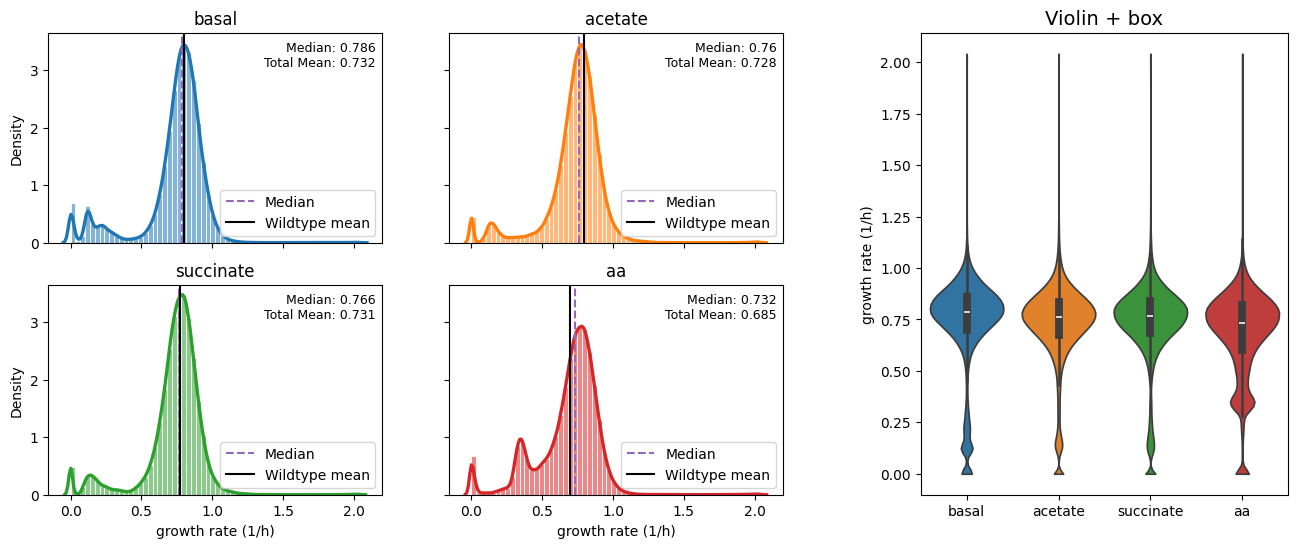

In [33]:
# Step 2: distribution of growth rate (1/h), all time points
# median point is indicated by a dashed line in the histograms
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

media = ["basal", "acetate", "succinate", "aa"]
palette = dict(zip(media, sns.color_palette("tab10", 4)))
LAB = "growth rate (1/h)"
central_line_color = sns.color_palette("tab10", 5)[-1]

# All time points (t > 0) of valid runs; trim rare extremes for plotting.
pts = d[d[TIME] > 0].merge(
    ps.loc[ps["valid_run"], ["medium", GENE, SEED]],
    on=["medium", GENE, SEED],
)
wildtype_mean = (pts[pts[GENE] == WILDTYPE].groupby(["medium", SEED])[VAL]
                 .mean().groupby("medium").mean())
lo, hi = pts[VAL].quantile([.005, .995])
pts = pts[(pts[VAL] >= lo) & (pts[VAL] <= hi)]
bin_edges = np.linspace(lo, hi, 61)

# Two main plots in one row: per-medium histograms on the left, violin plot on the right.
fig = plt.figure(figsize=(16, 6))
outer = fig.add_gridspec(1, 2, width_ratios=[2, 1], wspace=0.25)
hist_axes = outer[0, 0].subgridspec(2, 2).subplots(sharex=True, sharey=True)
violin_ax = fig.add_subplot(outer[0, 1])

for ax, medium in zip(hist_axes.flat, media):
    medium_pts = pts[pts["medium"] == medium]
    median = medium_pts[VAL].median()
    mean = medium_pts[VAL].mean()

    sns.histplot(
        data=medium_pts,
        x=VAL,
        bins=bin_edges,
        stat="density",
        element="bars",
        fill=True,
        alpha=0.55,
        color=palette[medium],
        edgecolor="white",
        linewidth=0.6,
        ax=ax,
    )
    sns.kdeplot(
        data=medium_pts,
        x=VAL,
        color=palette[medium],
        linewidth=2.4,
        ax=ax,
    )

    ax.axvline(median, color=central_line_color, linestyle="--", linewidth=1.5, label="Median")
    if medium in wildtype_mean.index:
        ax.axvline(wildtype_mean[medium], color="black", linewidth=1.5, label="Wildtype mean")
        ax.legend(loc="lower right")
    ax.text(
        0.98, 0.96, f"Median: {median:.3g}\nTotal Mean: {mean:.3g}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
    ax.set_title(medium)
    ax.set_xlabel(LAB)
    ax.set_ylabel("Density")

sns.violinplot(
    data=pts,
    x="medium",
    y=VAL,
    order=media,
    hue="medium",
    hue_order=media,
    palette=palette,
    legend=False,
    inner="box",
    cut=0,
    ax=violin_ax,
)
violin_ax.set_title("Violin + box", fontsize=14)
violin_ax.set_ylabel(LAB)
violin_ax.set_xlabel("")

fig.tight_layout()
fig.savefig(f"{OUT}/step2_timepoints_all.png", dpi=200, bbox_inches="tight")
plt.show()

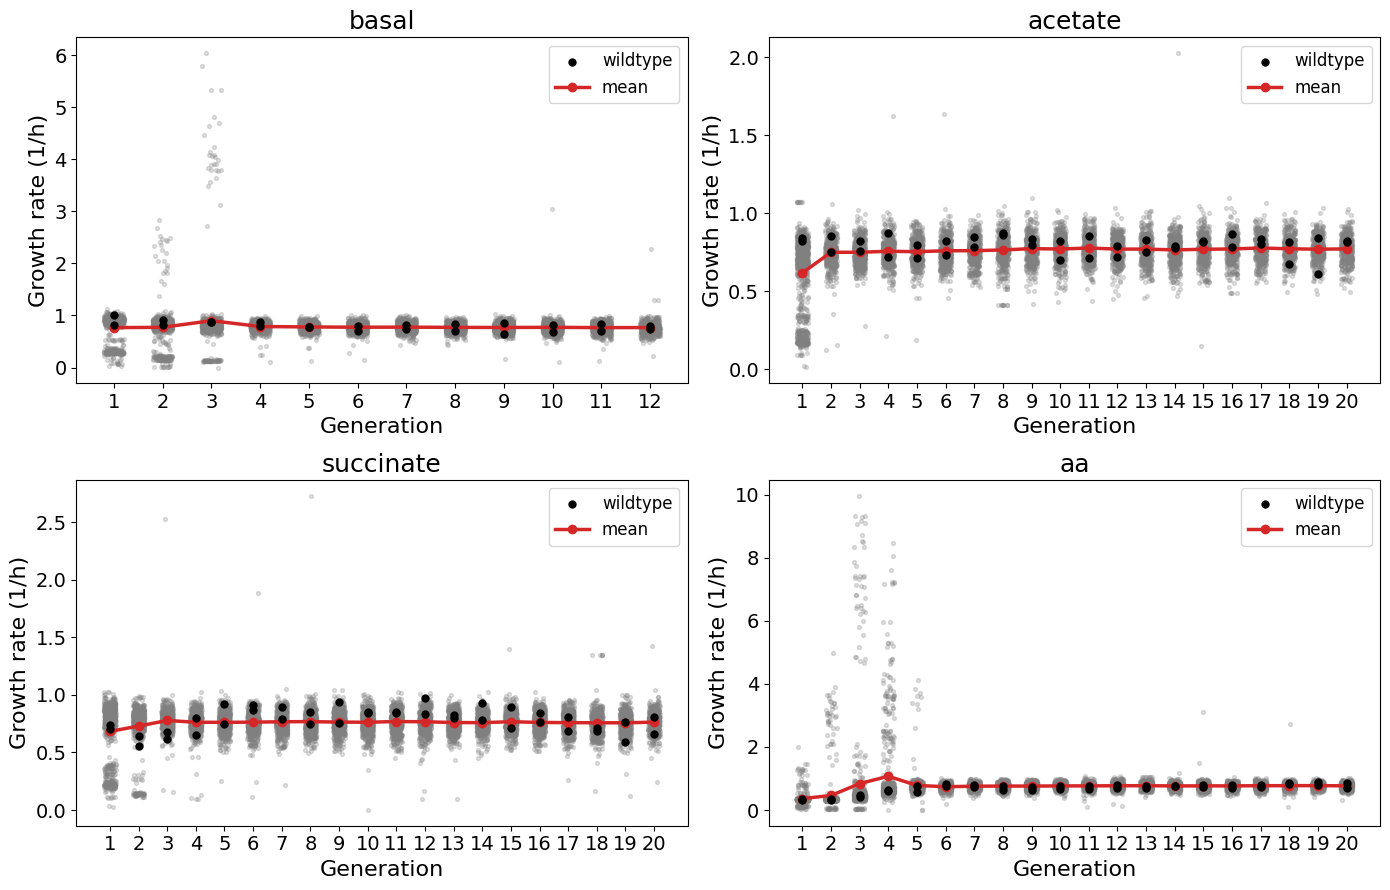

In [34]:
# Step 3: temporal pattern, growth rate (1/h) averaged within each generation
# One point per (KO, seed, generation) from valid runs; the line is the mean over those points.
MAX_GEN_PLOT = {"basal": 12, "acetate": 20, "succinate": 20, "aa": 20}
tp = d[d[TIME] > 0].merge(ps.loc[ps["valid_run"], ["medium", GENE, SEED]], on=["medium", GENE, SEED])
gen_mean = tp.groupby(["medium", GENE, SEED, GEN])[VAL].mean().reset_index(name="gen_mean")
gen_mean = gen_mean[gen_mean[GEN] <= gen_mean["medium"].map(MAX_GEN_PLOT)]
line = gen_mean.groupby(["medium", GEN])["gen_mean"].agg(mean="mean", n_runs="size").reset_index()
line.to_csv(f"{OUT}/step3_generation_mean_growth_rate.csv", index=False)

rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, m in zip(axes.flat, ["basal", "acetate", "succinate", "aa"]):
    g = gen_mean[gen_mean["medium"] == m]
    ko_g = g[g[GENE] != WILDTYPE]
    wt_g = g[g[GENE] == WILDTYPE]
    ax.scatter(ko_g[GEN] + rng.uniform(-0.2, 0.2, len(ko_g)), ko_g["gen_mean"], s=8, alpha=0.25, color="grey")
    ax.scatter(wt_g[GEN], wt_g["gen_mean"], s=25, color="black", zorder=5, label="wildtype")
    l = line[line["medium"] == m]
    ax.plot(l[GEN], l["mean"], color="C3", lw=2.5, marker="o", label="mean")
    ax.set_xticks(range(1, MAX_GEN_PLOT[m] + 1))
    ax.set_title(m, fontsize=18)
    ax.set_xlabel("Generation", fontsize=16)
    ax.set_ylabel("Growth rate (1/h)", fontsize=16)
    ax.tick_params(labelsize=14)
    ax.legend(fontsize=12)
plt.tight_layout()
plt.savefig(f"{OUT}/step3_temporal_pattern.png", dpi=200, bbox_inches="tight")
plt.show()


# Phase-2 Plan

**Goal:** quantify how media and gene knockouts jointly affect growth rate, and identify the KOs with the largest effects in each medium.

Two methods to compare with baseline (wildtype, basal condition): 1. substution, 2. log(targe/baseline).

1. **Data and preprocessing:** reuse the Phase-1 summary CSVs and growth-rate time-series parquet files for basal, acetate, succinate, and AA, including wildtype. Exclude AA seed 101 due to known errors. Ignore generation windows; calculate each valid run's mean over all available finite nonzero-time points and convert from 1/s to 1/h. Use the summary files to report missing runs and generations reached; do not treat early termination as failure or fill missing values with zero.
2. **Growth and KO effects:** average available seed-level means equally for each medium and KO. Compare each KO with the wildtype mean in the same medium (KO minus wildtype); rank the largest decreases and increases separately. Report seed counts and seed-level variation, and flag incomplete conditions.
3. **Media–KO interaction:** use basal as the reference and calculate, for each KO and other medium, `(KO − wildtype in medium) − (KO − wildtype in basal)`. Nonzero contrasts indicate that the KO effect depends on medium; describe these as deviations from additivity, not proof of biological synergy. Compare only observed conditions, report missing combinations, and assess sensitivity to seed variation; wildtype and KO seeds are not assumed paired.
4. **Visualization and outputs:** plot a 3D categorical scatter with medium and gene KO on the x/y axes and mean growth rate on z, highlighting wildtype. Add a medium-by-KO heatmap of interaction contrasts and per-medium ranked KO-effect plots. Export the per-condition growth, KO-effect and interaction tables with replicate counts; summarize the strongest effects and interactions. Interpret results cautiously because there are only two seeds and runs may cover different durations.

# Phase-2 Code

In [35]:
# Phase 2, Step 1: all-time-point run means and data availability
# Run Phase 1's preliminary analysis cell first (df, sim_status and summaries).
run_keys = ["medium", GENE, SEED]
summary = pd.concat(
    [s.assign(medium=m) for m, s in ko_summaries.items()]
    + [wt_summary.assign(medium=wt_summary["project"].map(wildtype_projects))],
    ignore_index=True,
)
if summary[run_keys].isna().any().any() or summary.duplicated(run_keys).any():
    raise ValueError("Missing or duplicate medium/KO/seed keys in summary data")

# Phase 1 excludes non-finite growth rates and constructed time-zero rows.
run_means = (
    df.groupby(run_keys)[VAL].mean().mul(3600)
    .reset_index(name="mean_growth_rate_per_hour")
)
phase2_runs = sim_status[run_keys + ["n_output_timepoints", "max_gen", "valid_run"]].merge(
    run_means, on=run_keys, how="left", validate="one_to_one"
)
phase2_runs.loc[~phase2_runs["valid_run"], "mean_growth_rate_per_hour"] = np.nan
phase2_runs = summary[run_keys + ["max_generation"]].merge(
    phase2_runs, on=run_keys, how="outer", indicator="data_availability", validate="one_to_one"
)
if ((phase2_runs["medium"] == "aa") & (phase2_runs[SEED] == 101)).any():
    raise ValueError("AA seed 101 must be excluded during dataset construction")
phase2_runs["run_type"] = np.where(phase2_runs[GENE] == WILDTYPE, "wildtype", "KO")
print("Run availability (left_only: summary only; right_only: time series only):")
display(phase2_runs.groupby(["medium", "run_type", "data_availability"], observed=True).size().unstack(fill_value=0))

# Candidate KO combinations absent from both files are not necessarily failed or submitted runs.
ko_labels = phase2_runs.loc[phase2_runs[GENE] != WILDTYPE, [GENE]].drop_duplicates()
candidate_runs = ko_labels.merge(pd.DataFrame({"medium": list(ko_summaries)}), how="cross")
candidate_seeds = phase2_runs.loc[phase2_runs[GENE] != WILDTYPE, ["medium", SEED]].drop_duplicates()
candidate_runs = candidate_runs.merge(candidate_seeds, on="medium", how="inner")
phase2_missing_runs = candidate_runs.merge(
    phase2_runs[run_keys], on=run_keys, how="left", indicator=True, validate="one_to_one"
).query("_merge == 'left_only'").drop(columns="_merge")
print("KO/seed combinations absent from both files (using observed seeds per medium):")
display(phase2_missing_runs.groupby("medium").size().reindex(list(ko_summaries), fill_value=0))
print("Maximum generations reached in the summary files:")
display(phase2_runs.groupby(["medium", "max_generation"]).size().unstack(fill_value=0))
print("Run-level growth means and generation details:")
display(phase2_runs.head())

Run availability (left_only: summary only; right_only: time series only):


data_availability   right_only  both
medium    run_type                  
aa        KO                 1   924
          wildtype           0     2
acetate   KO                 0   924
          wildtype           0     2
basal     KO                 0   924
          wildtype           0     2
succinate KO                 0   924
          wildtype           0     2

KO/seed combinations absent from both files (using observed seeds per medium):


medium
basal          0
acetate        0
succinate      0
aa           461
dtype: int64

Maximum generations reached in the summary files:


max_generation,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
medium,,,,,,,,,,,,,,,,,,,,
aa,141,10,64,98,15,5,1,3,3,3,5,4,2,1,4,2,5,2,3,555
acetate,430,9,4,2,8,2,4,6,5,3,12,3,6,10,6,5,6,2,3,400
basal,152,78,79,2,1,1,0,0,1,3,1,608,0,0,0,0,0,0,0,0
succinate,253,67,8,8,3,9,5,7,3,9,7,8,12,8,5,11,4,7,7,485


Run-level growth means and generation details:


,medium,label,lineage_seed,max_generation,n_output_timepoints,max_gen,valid_run,mean_growth_rate_per_hour,data_availability,run_type
0,aa,KO: EG10001,1,20.0,1098,20,True,0.701605,both,KO
1,aa,KO: EG10001,100,20.0,1143,20,True,0.683404,both,KO
2,aa,KO: EG10004,1,20.0,1056,20,True,0.727899,both,KO
3,aa,KO: EG10004,100,20.0,1096,20,True,0.720215,both,KO
4,aa,KO: EG10006,1,20.0,1100,20,True,0.695209,both,KO


In [36]:
# Phase 2, Step 2: per-condition growth and KO effects relative to wildtype
condition_keys = ["medium", GENE]
condition_grid = pd.concat([
    candidate_runs[condition_keys],
    phase2_runs.loc[phase2_runs[GENE] == WILDTYPE, condition_keys],
], ignore_index=True).drop_duplicates()
growth = phase2_runs.groupby(condition_keys)["mean_growth_rate_per_hour"].agg(
    mean_growth_rate="mean", n_valid_seeds="count", seed_sd="std"
).reset_index()
phase2_growth = condition_grid.merge(growth, on=condition_keys, how="left", validate="one_to_one")
phase2_growth["n_valid_seeds"] = phase2_growth["n_valid_seeds"].fillna(0).astype(int)
# Flag fewer than the original two seeds, including the excluded AA KO seed 101.
phase2_growth["incomplete"] = phase2_growth["n_valid_seeds"] < 2

wildtype = phase2_growth.loc[phase2_growth[GENE] == WILDTYPE, [
    "medium", "mean_growth_rate", "n_valid_seeds", "seed_sd", "incomplete"
]].rename(columns={
    "mean_growth_rate": "wildtype_mean_growth_rate",
    "n_valid_seeds": "wildtype_n_valid_seeds",
    "seed_sd": "wildtype_seed_sd",
    "incomplete": "wildtype_incomplete",
})
phase2_effects = phase2_growth.loc[phase2_growth[GENE] != WILDTYPE].merge(
    wildtype, on="medium", how="left", validate="many_to_one"
)
phase2_effects["wildtype_incomplete"] = phase2_effects["wildtype_incomplete"].fillna(True)
phase2_effects["effect_vs_wildtype"] = (
    phase2_effects["mean_growth_rate"] - phase2_effects["wildtype_mean_growth_rate"]
)
phase2_effects["comparison_incomplete"] = (
    phase2_effects["incomplete"] | phase2_effects["wildtype_incomplete"]
)

measured_effects = phase2_effects.dropna(subset=["effect_vs_wildtype"])
largest_decreases = (measured_effects[measured_effects["effect_vs_wildtype"] < 0]
    .sort_values("effect_vs_wildtype").groupby("medium", sort=False).head(5))
largest_increases = (measured_effects[measured_effects["effect_vs_wildtype"] > 0]
    .sort_values("effect_vs_wildtype", ascending=False).groupby("medium", sort=False).head(5))
display_columns = ["medium", GENE, "effect_vs_wildtype", "n_valid_seeds", "seed_sd", "comparison_incomplete"]
ranked_effects = pd.concat({"decrease": largest_decreases[display_columns], "increase": largest_increases[display_columns]}, names=["direction"])
phase2_effects.to_csv(
    "/user/home/il22158/work/vEcoli/reading/results/pattern/phase2_step2_KO_effect.csv", index=False
)
display(ranked_effects)

medium        label  effect_vs_wildtype  n_valid_seeds  \
direction                                                                   
decrease  741     acetate  KO: EG10774           -0.780412              2   
          740       basal  KO: EG10774           -0.776281              2   
          742   succinate  KO: EG10774           -0.743290              2   
          796       basal  KO: EG10807           -0.724061              2   
          536       basal  KO: EG10420           -0.721350              2   
          540       basal  KO: EG10421           -0.721350              2   
          808       basal  KO: EG10810           -0.718004              2   
          721     acetate  KO: EG10755           -0.705206              2   
          757     acetate  KO: EG10792           -0.700091              2   
          769     acetate  KO: EG10795           -0.700091              2   
          722   succinate  KO: EG10755           -0.666522              2   
          770   succinate  KO: EG10795           -0.662476              2   
          758   succinate  KO: EG10792           -0.662476              2   
          1047         aa  KO: EG10965           -0.662418              2   
          1255         aa  KO: EG11539           -0.661554              2   
          811          aa  KO: EG10810           -0.661429              2   
          543          aa  KO: EG10421           -0.661023              2   
          539          aa  KO: EG10420           -0.661023              2   
          653     acetate  KO: EG10586           -0.656820              2   
          642   succinate  KO: EG10581           -0.605832              2   
increase  1103         aa  KO: EG11030            3.129869              2   
          431          aa  KO: EG10196            3.092794              2   
          579          aa  KO: EG10453            2.882905              2   
          735          aa  KO: EG10770            2.870287              2   
          231          aa  KO: EG10094            2.849693              2   
          576       basal  KO: EG10453            0.928590              2   
          1100      basal  KO: EG11030            0.912219              2   
          428       basal  KO: EG10196            0.778841              2   
          588       basal  KO: EG10492            0.744571              2   
          1120      basal  KO: EG11043            0.727050              2   
          1698  succinate    KO: G7454            0.108007              2   
          1722  succinate    KO: G7533            0.088361              2   
          1702  succinate    KO: G7486            0.087277              2   
          1726  succinate    KO: G7542            0.074850              2   
          126   succinate  KO: EG10058            0.067814              2   
          1149    acetate  KO: EG11112            0.030275              2   
          1       acetate  KO: EG10001            0.021162              2   
          1329    acetate  KO: EG11810            0.016581              2   
          1501    acetate  KO: EG50006            0.014372              2   
          1705    acetate    KO: G7501            0.013551              2   

                 seed_sd  comparison_incomplete  
direction                                        
decrease  741   0.007379                  False  
          740   0.009857                  False  
          742   0.008838                  False  
          796   0.001321                  False  
          536   0.000805                  False  
          540   0.000805                  False  
          808   0.019629                  False  
          721   0.003468                  False  
          757   0.010470                  False  
          769   0.010470                  False  
          722   0.001721                  False  
          770   0.000447                  False  
          758   0.000447                  False  
          1047  0.002878          

In [37]:
# Phase 2, Step 3: media-KO interaction relative to basal
basal_effects = phase2_effects.loc[phase2_effects["medium"] == "basal", [
    GENE, "effect_vs_wildtype", "n_valid_seeds", "wildtype_n_valid_seeds", "comparison_incomplete"
]].rename(columns={
    "effect_vs_wildtype": "basal_effect",
    "n_valid_seeds": "basal_n_valid_seeds",
    "wildtype_n_valid_seeds": "basal_wildtype_n_valid_seeds",
    "comparison_incomplete": "basal_comparison_incomplete",
})
phase2_interactions = phase2_effects.loc[phase2_effects["medium"] != "basal"].merge(
    basal_effects, on=GENE, how="left", validate="many_to_one"
)
phase2_interactions["interaction"] = (
    phase2_interactions["effect_vs_wildtype"] - phase2_interactions["basal_effect"]
)
phase2_interactions["interaction_incomplete"] = (
    phase2_interactions["comparison_incomplete"]
    | phase2_interactions["basal_comparison_incomplete"].fillna(True)
)

# Sensitivity range: combine seed extrema independently, not a confidence interval.
# A single available seed gives no information about that condition's variability.
seed_range = phase2_runs.groupby(["medium", GENE])["mean_growth_rate_per_hour"].agg(
    seed_min="min", seed_max="max"
).reset_index()
wt_range = seed_range.loc[seed_range[GENE] == WILDTYPE, ["medium", "seed_min", "seed_max"]]
effect_range = seed_range.loc[seed_range[GENE] != WILDTYPE].merge(
    wt_range, on="medium", how="left", suffixes=("_ko", "_wt"), validate="many_to_one"
)
effect_range["effect_min"] = effect_range["seed_min_ko"] - effect_range["seed_max_wt"]
effect_range["effect_max"] = effect_range["seed_max_ko"] - effect_range["seed_min_wt"]
effect_range = effect_range[["medium", GENE, "effect_min", "effect_max"]]
basal_range = effect_range.loc[effect_range["medium"] == "basal", [GENE, "effect_min", "effect_max"]].rename(
    columns={"effect_min": "basal_effect_min", "effect_max": "basal_effect_max"}
)
phase2_interactions = phase2_interactions.merge(effect_range, on=["medium", GENE], how="left", validate="one_to_one")
phase2_interactions = phase2_interactions.merge(basal_range, on=GENE, how="left", validate="many_to_one")
phase2_interactions["interaction_min"] = phase2_interactions["effect_min"] - phase2_interactions["basal_effect_max"]
phase2_interactions["interaction_max"] = phase2_interactions["effect_max"] - phase2_interactions["basal_effect_min"]

phase2_interactions.to_csv(
    "/user/home/il22158/work/vEcoli/reading/results/pattern/phase2_step3_interactions.csv", index=False
)
availability = phase2_interactions.groupby("medium")["interaction"].agg(
    observed="count", total="size"
)
availability["missing"] = availability["total"] - availability["observed"]
display(availability)
strongest = phase2_interactions.dropna(subset=["interaction"]).assign(
    magnitude=lambda x: x["interaction"].abs()
).sort_values("magnitude", ascending=False).groupby("medium", sort=False).head(5)
display(strongest[["medium", GENE, "interaction", "interaction_min", "interaction_max", "interaction_incomplete"]])

,observed,total,missing
medium,,,
aa,406,462,56
acetate,406,462,56
succinate,406,462,56


,medium,label,interaction,interaction_min,interaction_max,interaction_incomplete
323,aa,KO: EG10196,2.313953,2.123529,2.504377,False
551,aa,KO: EG10770,2.252911,2.050164,2.455658,False
827,aa,KO: EG11030,2.217650,1.921291,2.514009,False
173,aa,KO: EG10094,2.143994,1.879767,2.408221,False
392,aa,KO: EG10407,2.112991,2.011776,2.214206,False
432,acetate,KO: EG10453,-1.479384,-1.539162,-1.419606,False
825,acetate,KO: EG11030,-1.458092,-1.564284,-1.351901,False
321,acetate,KO: EG10196,-1.333412,-1.389152,-1.277673,False
441,acetate,KO: EG10492,-1.303033,-1.592717,-1.013349,False
322,succinate,KO: EG10196,-1.283871,-1.327966,-1.239777,False


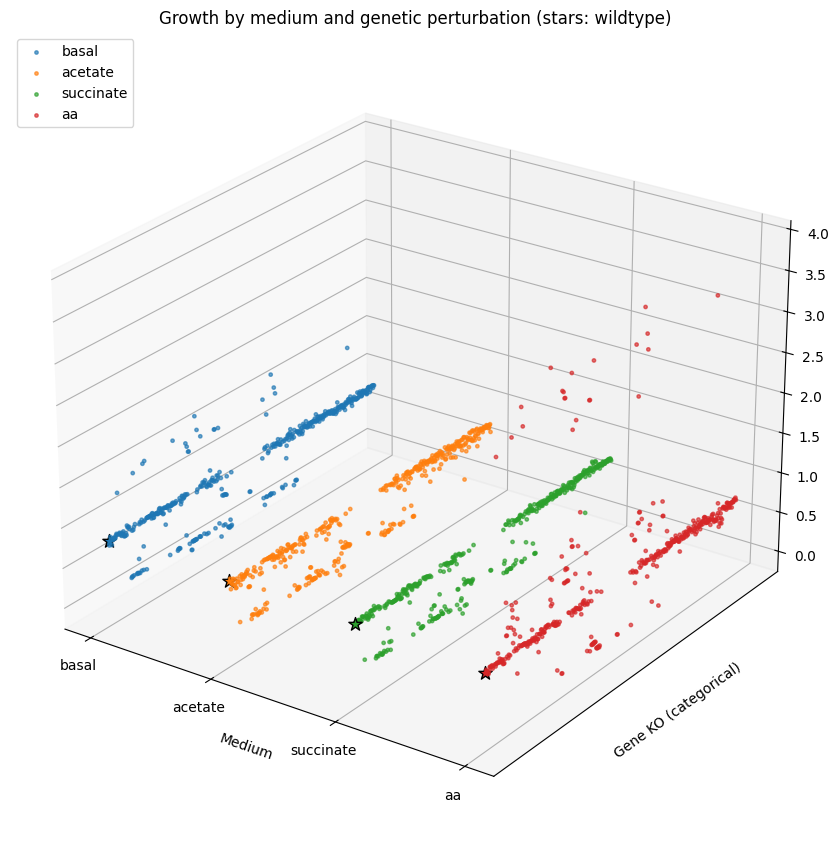

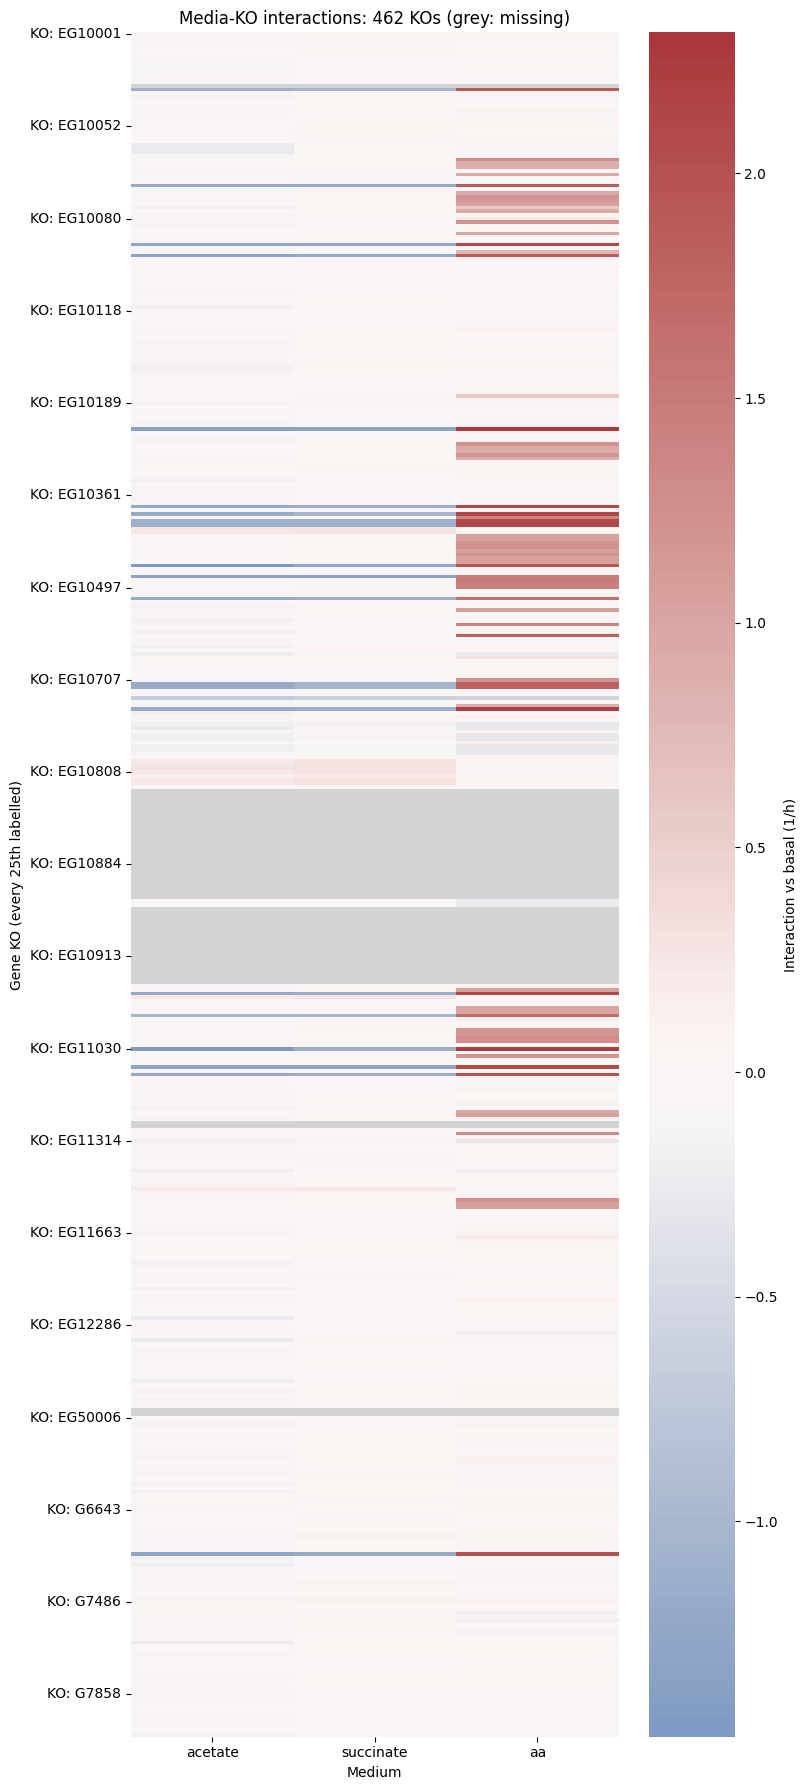

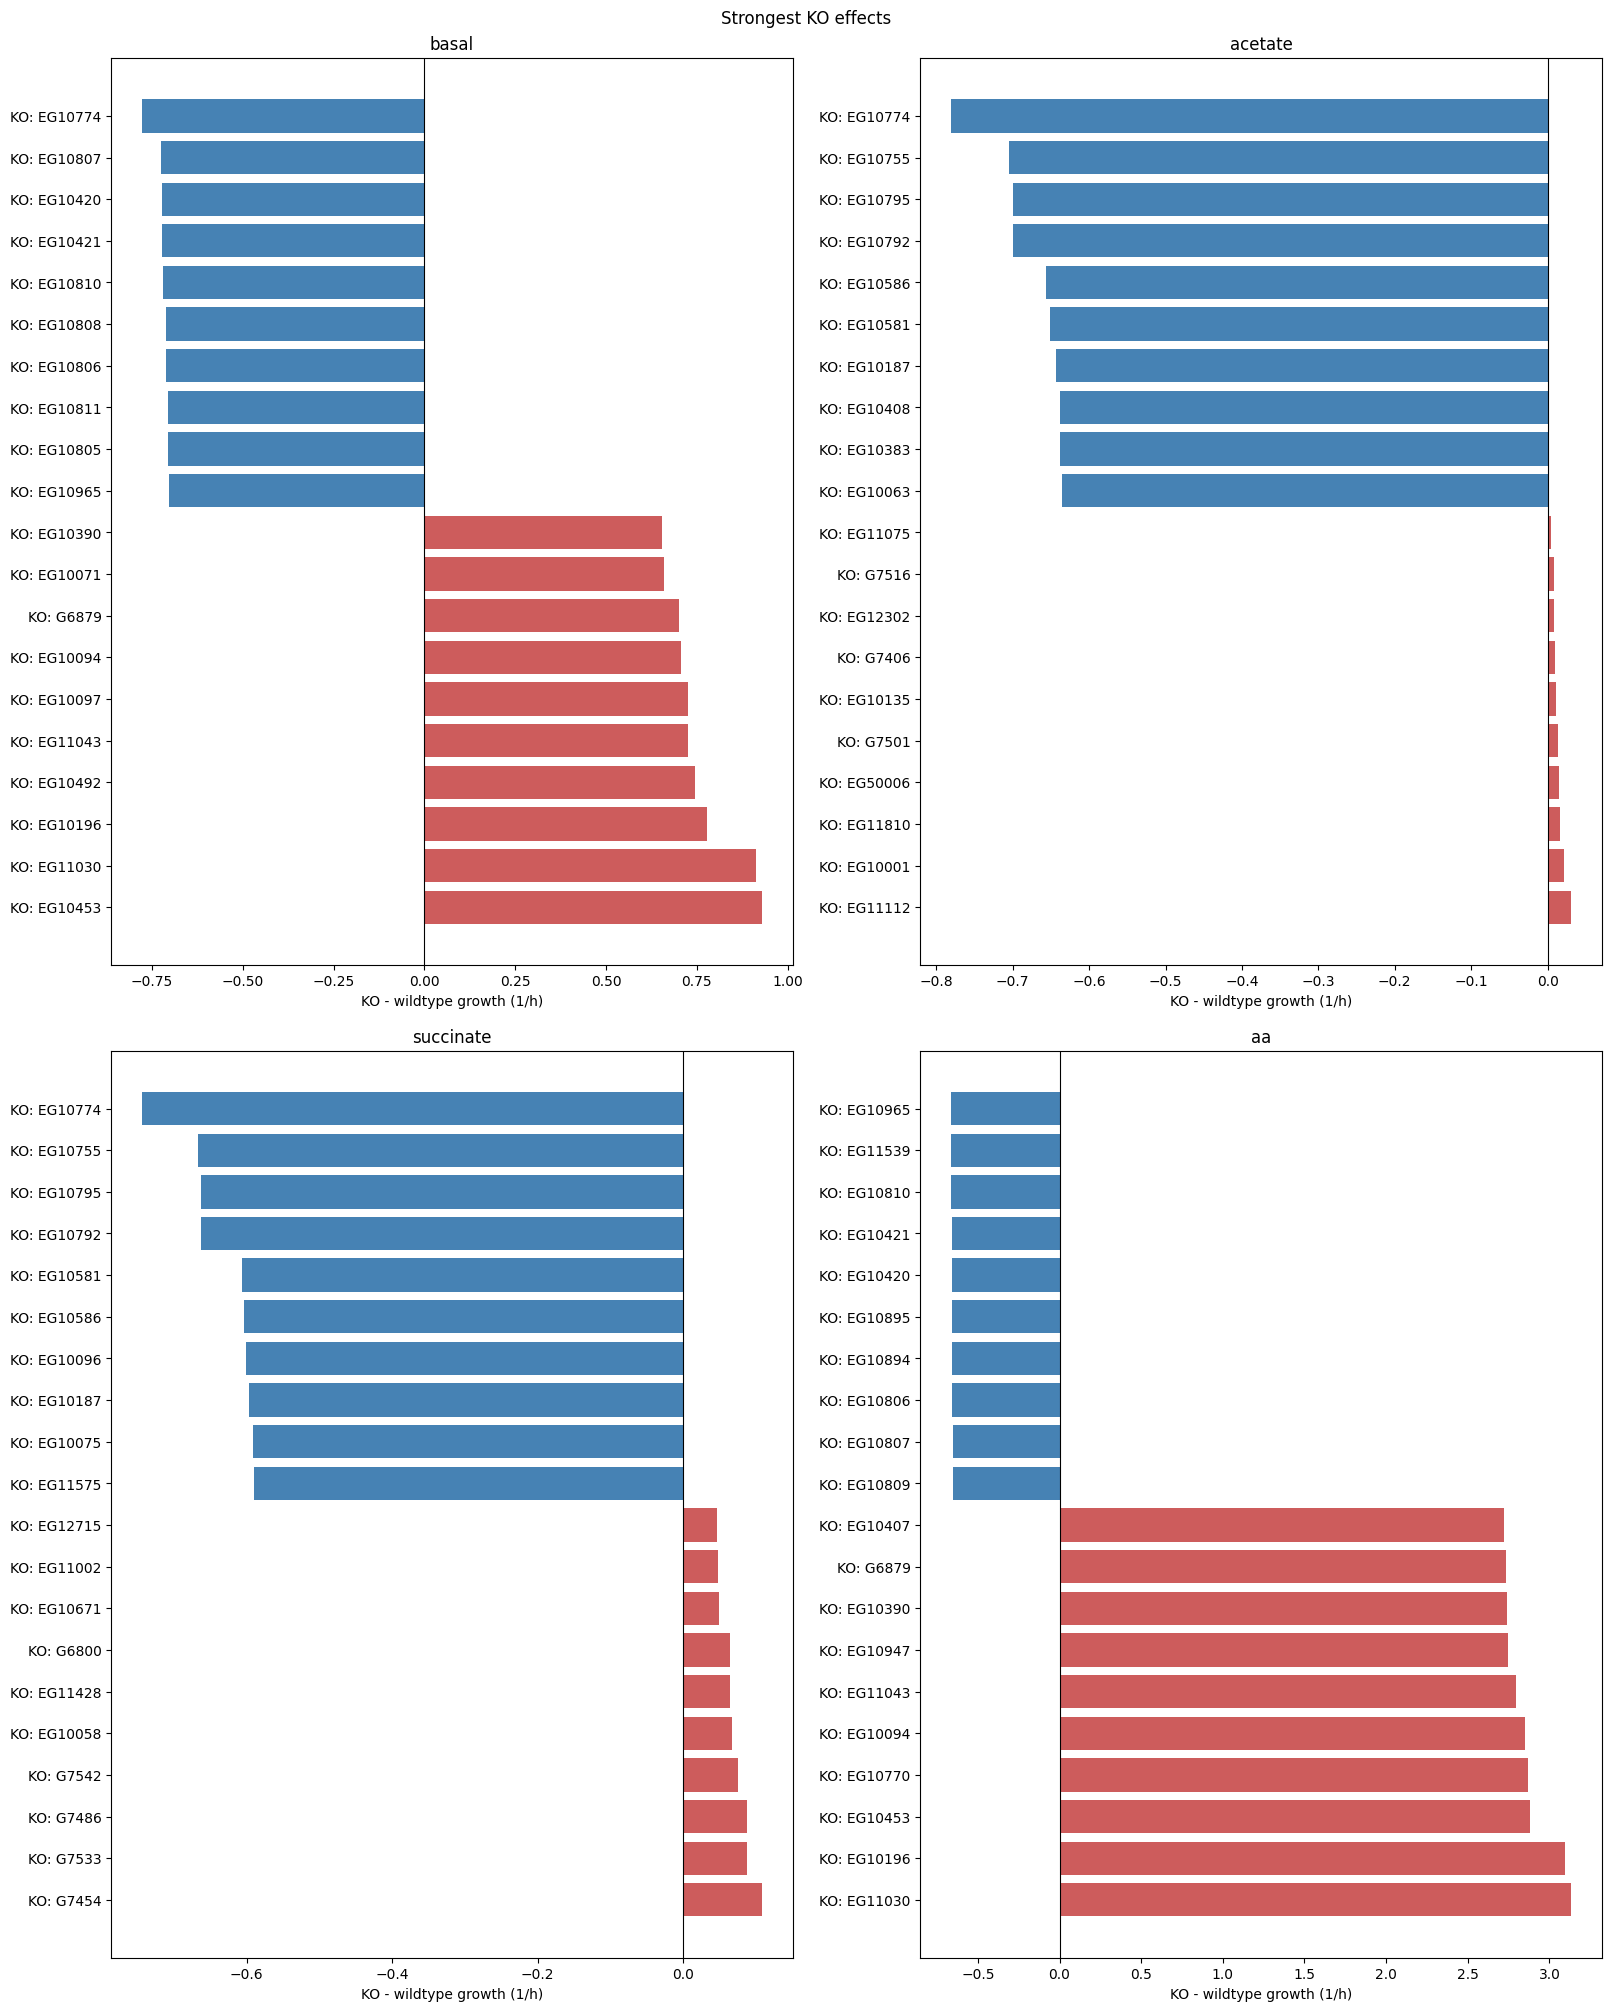

Strongest effects and interactions are shown in Steps 2 and 3. Hatched effects have fewer than two valid seeds; AA KO seed 101 is excluded. Seed-extrema ranges are not confidence intervals, and differing run durations can affect comparisons.


In [38]:
# Phase 2, Step 4: growth, KO effects and media-KO interactions
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

phase2_out = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
phase2_out.mkdir(parents=True, exist_ok=True)
phase2_growth.to_csv(phase2_out / "phase2_step4_growth.csv", index=False)
media = ["basal", "acetate", "succinate", "aa"]
genes = sorted(phase2_growth.loc[phase2_growth[GENE] != WILDTYPE, GENE].unique())
gene_positions = {gene: i for i, gene in enumerate([WILDTYPE] + genes)}
medium_positions = {medium: i for i, medium in enumerate(media)}

# All observed conditions; y-axis positions are categorical, not a continuous gene scale.
growth_plot = phase2_growth.dropna(subset=["mean_growth_rate"])
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
for medium, color in zip(media, sns.color_palette("tab10", 4)):
    points = growth_plot[(growth_plot["medium"] == medium) & (growth_plot[GENE] != WILDTYPE)]
    ax.scatter(points["medium"].map(medium_positions), points[GENE].map(gene_positions),
               points["mean_growth_rate"], color=color, s=6, alpha=0.65, label=medium)
    wt_points = growth_plot[(growth_plot["medium"] == medium) & (growth_plot[GENE] == WILDTYPE)]
    ax.scatter(wt_points["medium"].map(medium_positions), wt_points[GENE].map(gene_positions),
               wt_points["mean_growth_rate"], color=color, marker="*", s=100, edgecolors="black")
ax.set_xticks(range(len(media)), media)
ax.set_yticks([])
ax.set(xlabel="Medium", ylabel="Gene KO (categorical)", zlabel="Mean growth rate (1/h)",
       title="Growth by medium and genetic perturbation (stars: wildtype)")
ax.view_init(elev=25, azim=-55)
ax.zaxis.labelpad = 12
ax.legend(loc="upper left", bbox_to_anchor=(0, 1))
fig.subplots_adjust(left=0.02, right=0.92, bottom=0.04, top=0.94)
fig.savefig(phase2_out / "phase2_step4_growth_3d.png", dpi=200, bbox_inches="tight")
plt.show()

# Missing comparisons remain blank; basal is the reference, not an interaction column.
interaction_matrix = phase2_interactions.pivot(index=GENE, columns="medium", values="interaction")
interaction_matrix = interaction_matrix.reindex(index=genes, columns=media[1:])
fig, ax = plt.subplots(figsize=(8, 18))
ax.set_facecolor("lightgrey")
sns.heatmap(interaction_matrix, cmap="vlag", center=0, mask=interaction_matrix.isna(),
            yticklabels=25, cbar_kws={"label": "Interaction vs basal (1/h)"}, ax=ax)
ax.set(title=f"Media-KO interactions: {len(genes)} KOs (grey: missing)", xlabel="Medium", ylabel="Gene KO (every 25th labelled)")
fig.tight_layout()
fig.savefig(phase2_out / "phase2_step4_interaction_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

# Show the ten strongest decreases and increases in each medium.
fig, axes = plt.subplots(2, 2, figsize=(16, 20), constrained_layout=True)
for medium, ax in zip(media, axes.flat):
    effects = phase2_effects.loc[
        (phase2_effects["medium"] == medium) & phase2_effects["effect_vs_wildtype"].notna()
    ].sort_values("effect_vs_wildtype")
    extremes = pd.concat([effects[effects["effect_vs_wildtype"] < 0].head(10),
                          effects[effects["effect_vs_wildtype"] > 0].tail(10)])
    bars = ax.barh(extremes[GENE], extremes["effect_vs_wildtype"],
                   color=np.where(extremes["effect_vs_wildtype"] < 0, "steelblue", "indianred"))
    for bar, incomplete in zip(bars, extremes["comparison_incomplete"]):
        if incomplete:
            bar.set_hatch("//")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=medium, xlabel="KO - wildtype growth (1/h)")
fig.suptitle("Strongest KO effects")
fig.savefig(phase2_out / "phase2_step4_ko_effects.png", dpi=200, bbox_inches="tight")
plt.show()

print("Strongest effects and interactions are shown in Steps 2 and 3. Hatched effects have fewer than two valid seeds; AA KO seed 101 is excluded. Seed-extrema ranges are not confidence intervals, and differing run durations can affect comparisons.")

,observed,total,missing
medium,,,
aa,406,462,56
acetate,406,462,56
succinate,406,462,56


,medium,label,log_interaction,log_interaction_min,log_interaction_max,interaction_incomplete
491,aa,KO: EG10586,2.554937,2.494810,2.615950,False
482,aa,KO: EG10581,2.319797,2.154201,2.474614,False
395,aa,KO: EG10408,2.293693,2.180138,2.406334,False
446,aa,KO: EG10495,2.285969,2.087013,2.469915,False
452,aa,KO: EG10497,2.253423,2.115035,2.401036,False
540,acetate,KO: EG10755,-2.124463,-2.223444,-2.024021,False
541,succinate,KO: EG10755,-1.963970,-2.024736,-1.902542,False
432,acetate,KO: EG10453,-1.943906,-2.021924,-1.864645,False
825,acetate,KO: EG11030,-1.914660,-2.022173,-1.804860,False
841,succinate,KO: EG11043,-1.910719,-2.083955,-1.754811,False


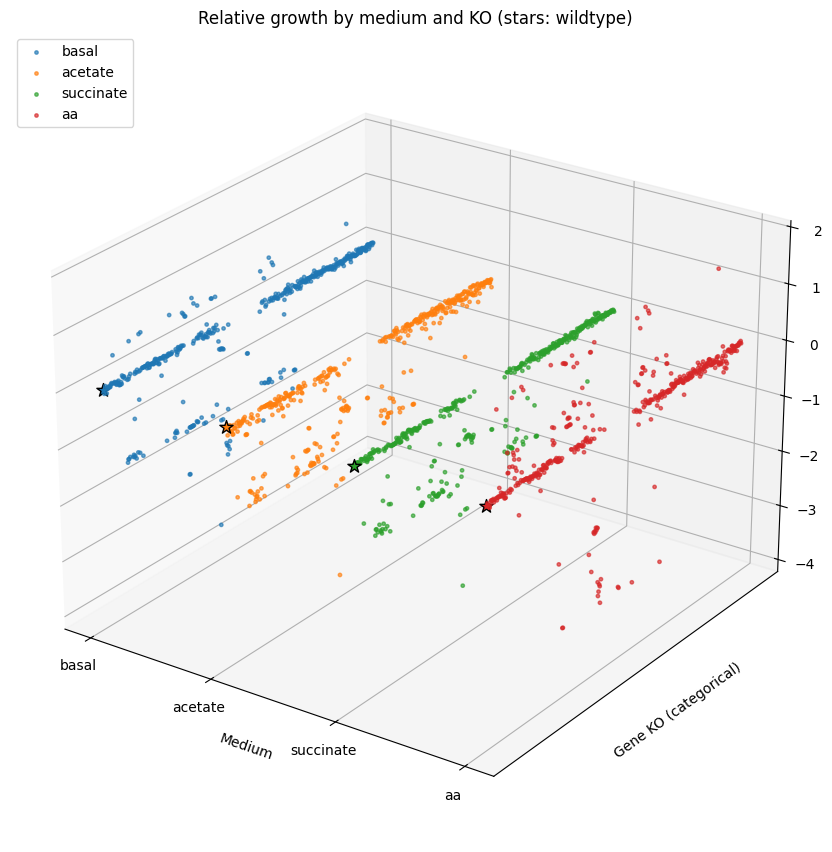

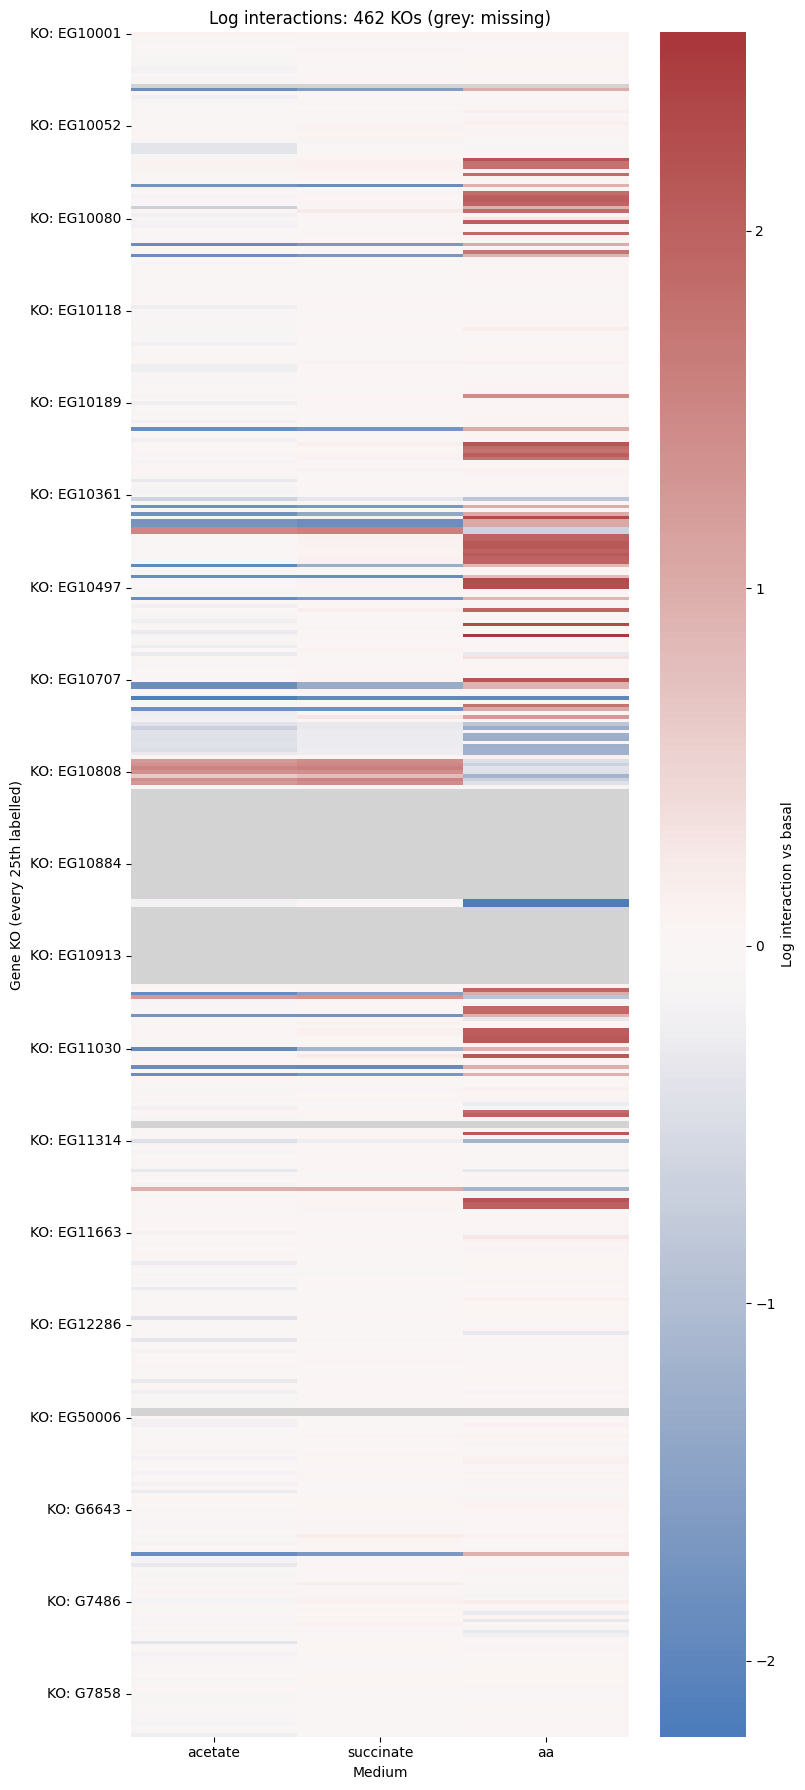

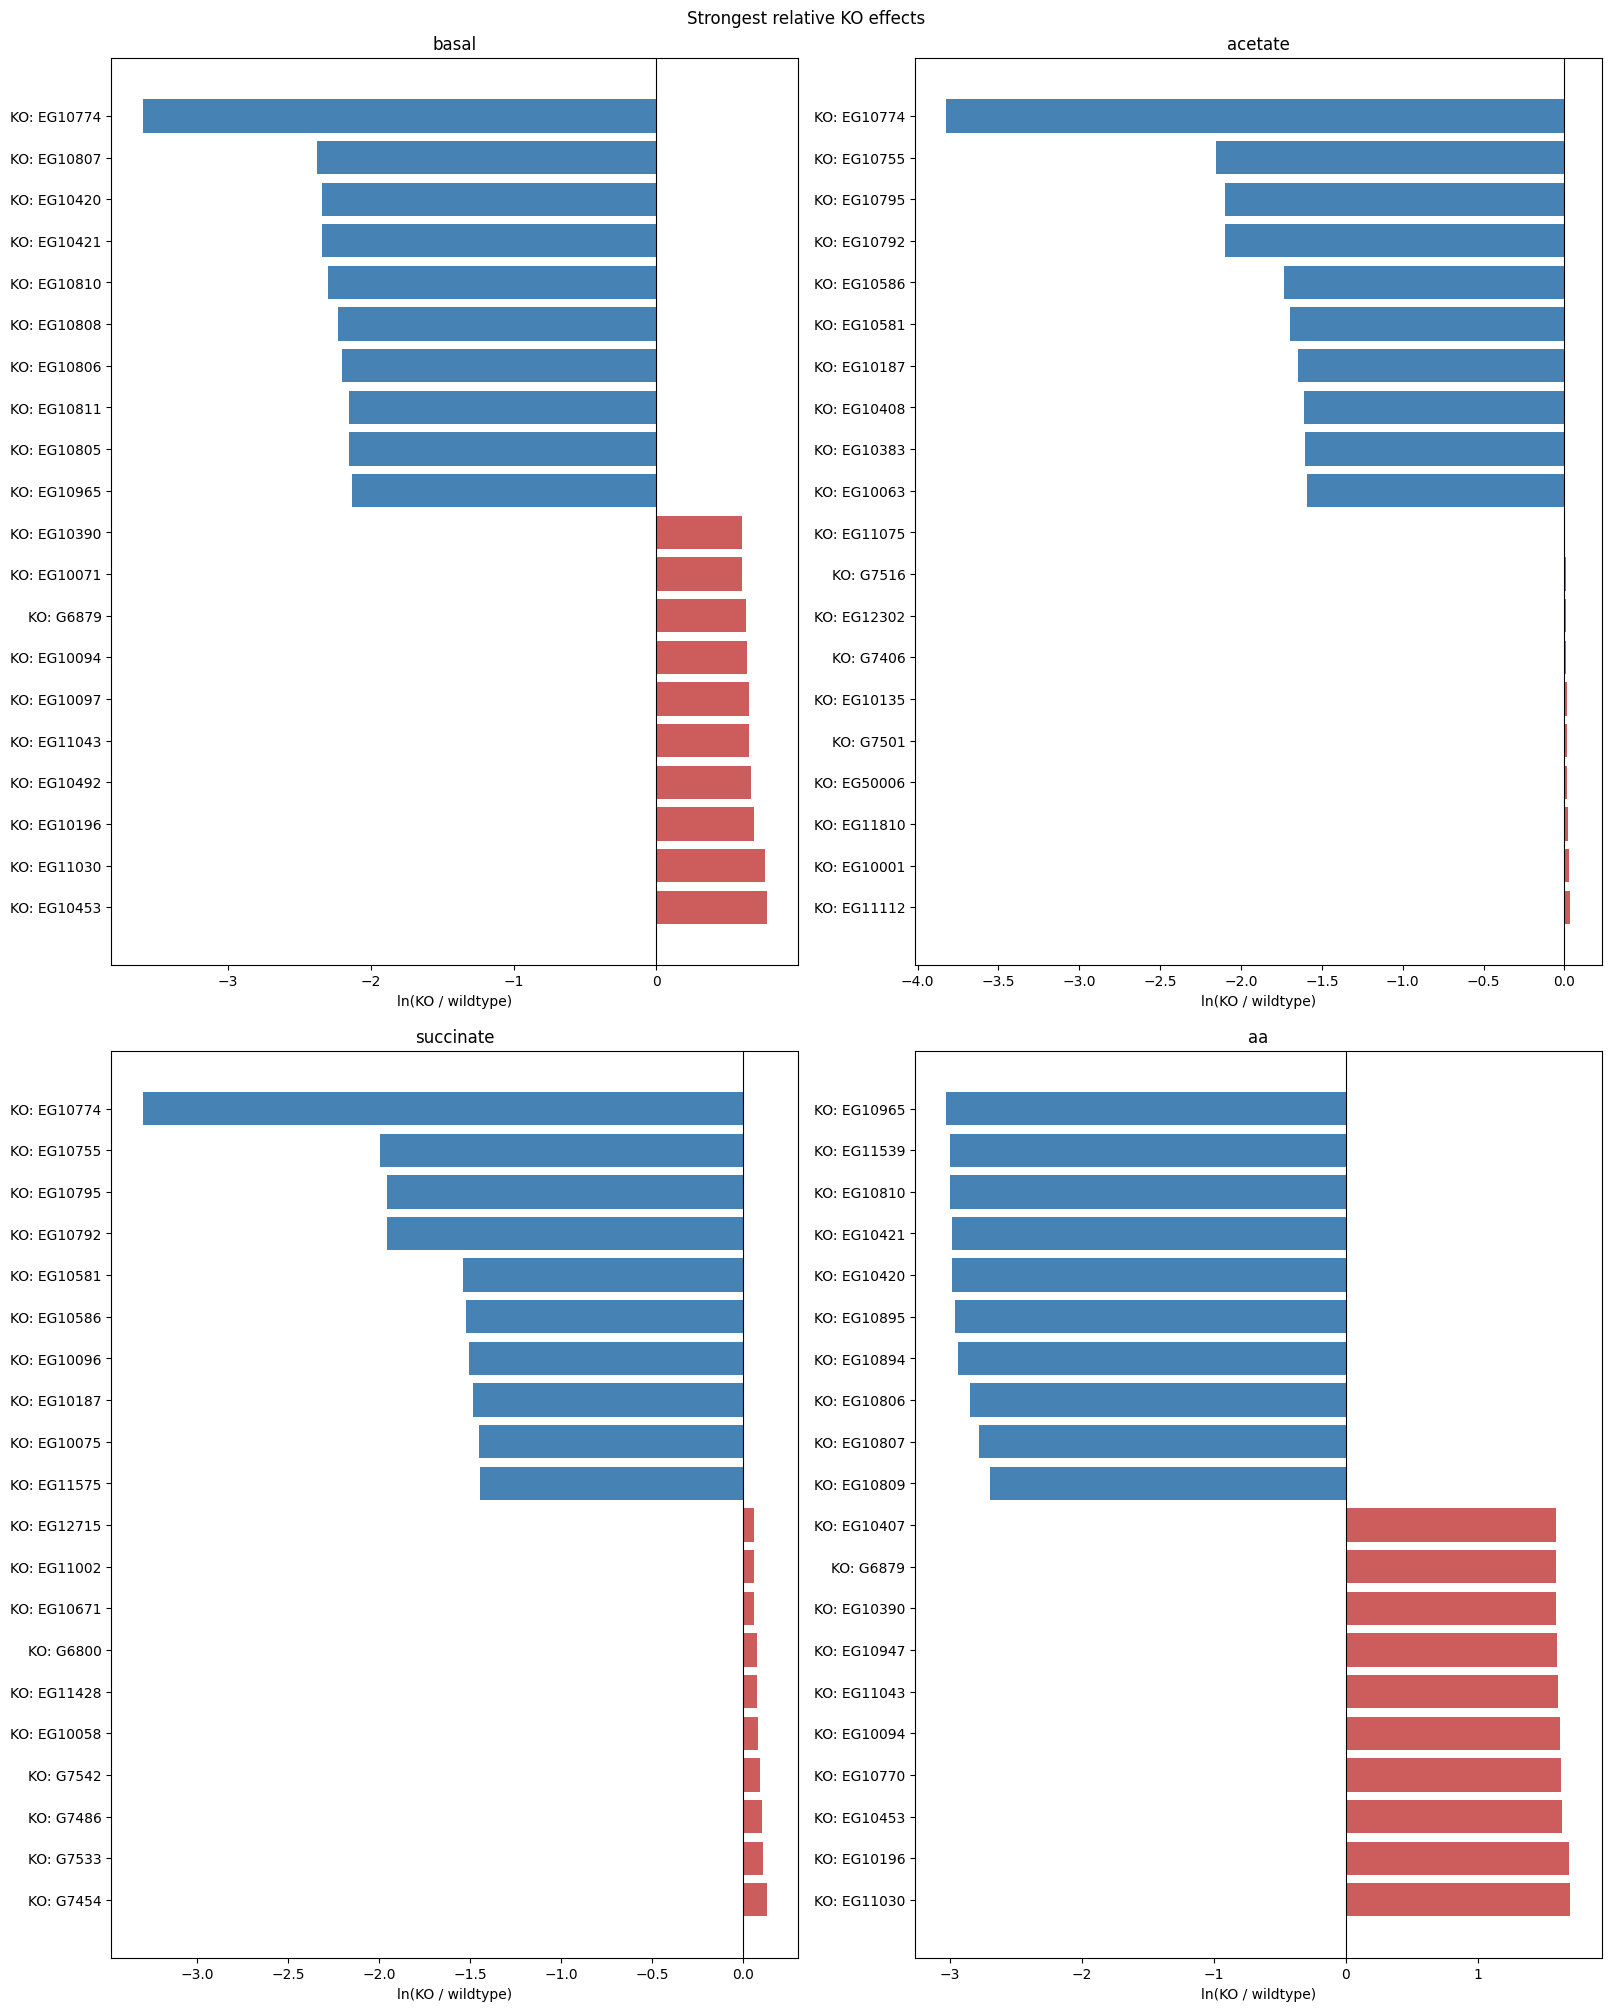

Log ratios describe relative effects, not proof of synergy. Single-seed conditions do not measure seed variability; run durations may differ.


In [39]:
# Phase 2, Step 3b: natural-log KO/wildtype ratios and interactions
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

log_out = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
log_out.mkdir(parents=True, exist_ok=True)
log_media = ["basal", "acetate", "succinate", "aa"]
log_effects = phase2_effects.copy()
ko_mean = log_effects["mean_growth_rate"]
wt_mean = log_effects["wildtype_mean_growth_rate"]
bad_means = (ko_mean.notna() & (ko_mean <= 0)) | (wt_mean.notna() & (wt_mean <= 0))
if bad_means.any():
    print(f"Nonpositive growth means: {bad_means.sum()} comparisons cannot use log ratios.")
log_effects["log_ko_wt"] = np.log(ko_mean.where(ko_mean > 0)) - np.log(wt_mean.where(wt_mean > 0))

basal_log = log_effects.loc[log_effects["medium"] == "basal", [
    GENE, "log_ko_wt", "n_valid_seeds", "wildtype_n_valid_seeds", "comparison_incomplete"
]].rename(columns={
    "log_ko_wt": "basal_log_ko_wt", "n_valid_seeds": "basal_n_valid_seeds",
    "wildtype_n_valid_seeds": "basal_wildtype_n_valid_seeds",
    "comparison_incomplete": "basal_comparison_incomplete",
})
log_interactions = log_effects.loc[log_effects["medium"] != "basal"].merge(
    basal_log, on=GENE, how="left", validate="many_to_one"
)
log_interactions["log_interaction"] = log_interactions["log_ko_wt"] - log_interactions["basal_log_ko_wt"]
log_interactions["interaction_incomplete"] = (
    log_interactions["comparison_incomplete"] | log_interactions["basal_comparison_incomplete"].fillna(True)
)

# Extrema vary seeds independently; these bounds are not confidence intervals.
log_seed_range = phase2_runs.groupby(["medium", GENE])["mean_growth_rate_per_hour"].agg(
    seed_min="min", seed_max="max"
).reset_index()
bad_seeds = log_seed_range["seed_min"].notna() & (log_seed_range["seed_min"] <= 0)
if bad_seeds.any():
    print(f"Nonpositive seed means: {bad_seeds.sum()} conditions have undefined log sensitivity bounds.")
log_seed_range["log_min"] = np.log(log_seed_range["seed_min"].where(log_seed_range["seed_min"] > 0))
log_seed_range["log_max"] = np.log(log_seed_range["seed_max"].where(log_seed_range["seed_min"] > 0))
log_wt_range = log_seed_range.loc[log_seed_range[GENE] == WILDTYPE, ["medium", "log_min", "log_max"]]
log_range = log_seed_range.loc[log_seed_range[GENE] != WILDTYPE].merge(
    log_wt_range, on="medium", how="left", suffixes=("_ko", "_wt"), validate="many_to_one"
)
log_range["log_effect_min"] = log_range["log_min_ko"] - log_range["log_max_wt"]
log_range["log_effect_max"] = log_range["log_max_ko"] - log_range["log_min_wt"]
log_range = log_range[["medium", GENE, "log_effect_min", "log_effect_max"]]
basal_log_range = log_range.loc[log_range["medium"] == "basal", [GENE, "log_effect_min", "log_effect_max"]].rename(
    columns={"log_effect_min": "basal_log_effect_min", "log_effect_max": "basal_log_effect_max"}
)
log_interactions = log_interactions.merge(log_range, on=["medium", GENE], how="left", validate="one_to_one")
log_interactions = log_interactions.merge(basal_log_range, on=GENE, how="left", validate="many_to_one")
log_interactions["log_interaction_min"] = log_interactions["log_effect_min"] - log_interactions["basal_log_effect_max"]
log_interactions["log_interaction_max"] = log_interactions["log_effect_max"] - log_interactions["basal_log_effect_min"]
log_effects.to_csv(log_out / "phase2_step3b_log_KO_effect.csv", index=False)
log_interactions.to_csv(log_out / "phase2_step3b_log_interactions.csv", index=False)
log_availability = log_interactions.groupby("medium")["log_interaction"].agg(observed="count", total="size")
log_availability["missing"] = log_availability["total"] - log_availability["observed"]
display(log_availability)
log_strongest = log_interactions.dropna(subset=["log_interaction"]).assign(
    magnitude=lambda x: x["log_interaction"].abs()
).sort_values("magnitude", ascending=False).groupby("medium", sort=False).head(5)
display(log_strongest[["medium", GENE, "log_interaction", "log_interaction_min", "log_interaction_max", "interaction_incomplete"]])

# Use the same categorical layout as Step 4, with log KO/wildtype on the z-axis.
log_genes = sorted(log_effects[GENE].unique())
log_positions = {gene: i for i, gene in enumerate([WILDTYPE] + log_genes)}
fig = plt.figure(figsize=(14, 9))
ax = fig.add_subplot(111, projection="3d")
for i, (medium, color) in enumerate(zip(log_media, sns.color_palette("tab10", 4))):
    points = log_effects[(log_effects["medium"] == medium) & log_effects["log_ko_wt"].notna()]
    ax.scatter(np.full(len(points), i), points[GENE].map(log_positions), points["log_ko_wt"],
               color=color, s=6, alpha=0.65, label=medium)
    wt = phase2_growth[(phase2_growth["medium"] == medium) & (phase2_growth[GENE] == WILDTYPE)]
    if wt["mean_growth_rate"].gt(0).any():
        ax.scatter([i], [0], [0], color=color, marker="*", s=100, edgecolors="black")
ax.set_xticks(range(len(log_media)), log_media)
ax.set_yticks([])
ax.set(xlabel="Medium", ylabel="Gene KO (categorical)", zlabel="ln(KO / wildtype)",
       title="Relative growth by medium and KO (stars: wildtype)")
ax.view_init(elev=25, azim=-55)
ax.zaxis.labelpad = 12
ax.legend(loc="upper left", bbox_to_anchor=(0, 1))
fig.subplots_adjust(left=0.02, right=0.92, bottom=0.04, top=0.94)
fig.savefig(log_out / "phase2_step3b_log_growth_3d.png", dpi=200, bbox_inches="tight")
plt.show()

log_matrix = log_interactions.pivot(index=GENE, columns="medium", values="log_interaction")
log_matrix = log_matrix.reindex(index=log_genes, columns=log_media[1:])
fig, ax = plt.subplots(figsize=(8, 18))
ax.set_facecolor("lightgrey")
sns.heatmap(log_matrix, cmap="vlag", center=0, mask=log_matrix.isna(), yticklabels=25,
            cbar_kws={"label": "Log interaction vs basal"}, ax=ax)
ax.set(title=f"Log interactions: {len(log_genes)} KOs (grey: missing)",
       xlabel="Medium", ylabel="Gene KO (every 25th labelled)")
fig.tight_layout()
fig.savefig(log_out / "phase2_step3b_log_interaction_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(16, 20), constrained_layout=True)
for medium, ax in zip(log_media, axes.flat):
    effects = log_effects.loc[(log_effects["medium"] == medium) & log_effects["log_ko_wt"].notna()].sort_values("log_ko_wt")
    extremes = pd.concat([effects[effects["log_ko_wt"] < 0].head(10),
                          effects[effects["log_ko_wt"] > 0].tail(10)])
    bars = ax.barh(extremes[GENE], extremes["log_ko_wt"],
                   color=np.where(extremes["log_ko_wt"] < 0, "steelblue", "indianred"))
    for bar, incomplete in zip(bars, extremes["comparison_incomplete"]):
        if incomplete:
            bar.set_hatch("//")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.invert_yaxis()
    ax.set(title=medium, xlabel="ln(KO / wildtype)")
fig.suptitle("Strongest relative KO effects")
fig.savefig(log_out / "phase2_step3b_log_KO_effects.png", dpi=200, bbox_inches="tight")
plt.show()
print("Log ratios describe relative effects, not proof of synergy. Single-seed conditions do not measure seed variability; run durations may differ.")

# Phase-3 Plan

- Aim: connect Phase 1/2 patterns to testable biological hypotheses and identify a knowledge-guided ML model that complements whole-cell modeling.

- Media details: [condition definitions](../reconstruction/ecoli/flat/condition/condition_defs.tsv) and [media recipes](../reconstruction/ecoli/flat/condition/media_recipes.tsv).

- Pathway references: [EcoCyc](https://ecocyc.org/) and [KEGG](https://www.kegg.jp/).

- Further study based on Phase 1 and Phase 2 results:

**Practical next step:** use EcoCyc/KEGG to map the strongest KO candidates to pathways, then test a small panel (`dapA`, `glyA`, `ilvE`, `ppa`, and selected synthetases) across all four media with matched run durations and additional seeds. Resolve the AA seed issue first: its Phase 2 KO comparisons currently rely on one seed, and Phase 1 has no AA KO seed pairs in the selected window. Test whether amino-acid supplementation selectively rescues biosynthesis-KO growth effects.\
Note in phase-2 discussion the gene ids are already converted to common gene names so ready for a search.

- Possible Future directions:

**ML follow-up:** predict the KO-by-medium interaction from pathway membership, media nutrients, and condition-specific TFs; evaluate on held-out genes/pathways and compare predicted effects with new whole-cell simulations. Treat incomplete runs and seed variation explicitly.


RxazN!7_mE

In [44]:
# Test BioCyc authorization with a single documented EcoCyc gene request.
from getpass import getpass
from time import sleep
from xml.etree import ElementTree as ET
import requests

email = input("BioCyc account email: ")
password = getpass("BioCyc password: ")
biocyc_session = requests.Session()
try:
    login = biocyc_session.post(
        "https://websvc.biocyc.org/credentials/login/",
        data={"email": email, "password": password}, timeout=30,
    )
    login.raise_for_status()
finally:
    del email, password

if not biocyc_session.cookies:
    raise RuntimeError("BioCyc did not return a session cookie; check the login.")

sleep(1)
response = biocyc_session.get(
    "https://websvc.biocyc.org/getxml",
    params={"id": "ECOLI:EG11025", "detail": "low"}, timeout=30,
)
response.raise_for_status()
try:
    root = ET.fromstring(response.content)
except ET.ParseError as exc:
    raise ValueError("BioCyc returned non-XML; check account access.") from exc
gene = root.find("Gene")
if root.tag != "ptools-xml" or root.find("Error") is not None or gene is None or gene.get("frameid") != "EG11025":
    raise ValueError("BioCyc did not return the requested gene; check account access.")
print("BioCyc authorization successful: retrieved EcoCyc gene EG11025.")

BioCyc authorization successful: retrieved EcoCyc gene EG11025.


In [45]:
# Search BioCyc for the candidates selected in the Phase 2 discussion, not every gene.
# Phase 2 tables supply their gene IDs and medium-specific scores and completeness flags,
# so the retrieved annotations can be compared with the simulation results.

from pathlib import Path
from getpass import getpass
from time import monotonic, sleep
from xml.etree import ElementTree as ET

import pandas as pd
import requests
from IPython.display import display

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
candidates = pd.read_csv(results_dir / "phase2_top_influencer.csv")["gene_name"].dropna().unique().tolist()
files = {
    "additive_effect": ("phase2_step2_KO_effect.csv", "effect_vs_wildtype", "comparison_incomplete"),
    "additive_interaction": ("phase2_step3_interactions.csv", "interaction", "interaction_incomplete"),
    "log_effect": ("phase2_step3b_log_KO_effect.csv", "log_ko_wt", "comparison_incomplete"),
    "log_interaction": ("phase2_step3b_log_interactions.csv", "log_interaction", "interaction_incomplete"),
}

tables = {}
for name, (file_name, score, incomplete) in files.items():
    table = pd.read_csv(results_dir / file_name)
    tables[name] = table.loc[table["gene_name"].isin(candidates), [
        "medium", "gene_id", "gene_name", score, incomplete
    ]].rename(columns={score: name, incomplete: f"{name}_incomplete"})

gene_ids = tables["additive_effect"][["gene_id", "gene_name"]].drop_duplicates()
if set(gene_ids["gene_name"]) != set(candidates) or gene_ids["gene_name"].duplicated().any():
    raise ValueError("Candidate gene names must each match exactly one gene ID in the Phase 2 results.")

comparison = tables["additive_effect"]
for name in ("additive_interaction", "log_effect", "log_interaction"):
    comparison = comparison.merge(tables[name], on=["medium", "gene_id", "gene_name"],
                                  how="left", validate="one_to_one")

# BioCyc requires an authenticated session; credentials are not saved to the notebook.
email = input("BioCyc account email: ")
password = getpass("BioCyc password: ")
session = requests.Session()
last_request = 0.0

def biocyc_request(method, path, **kwargs):
    global last_request
    sleep(max(0.0, 1.0 - (monotonic() - last_request)))
    last_request = monotonic()
    response = session.request(method, f"https://websvc.biocyc.org/{path}", timeout=30, **kwargs)
    response.raise_for_status()
    return response

login = biocyc_request("POST", "credentials/login/", data={"email": email, "password": password})
del email, password
if not session.cookies:
    raise RuntimeError("BioCyc login did not return a session cookie; check account access.")

def biocyc_objects(gene_id, function, object_type):
    response = biocyc_request("GET", "apixml", params={
        "fn": function, "id": f"ECOLI:{gene_id}", "detail": "low"
    })
    try:
        root = ET.fromstring(response.content)
    except ET.ParseError as exc:
        raise ValueError(f"BioCyc returned non-XML for {gene_id} ({function}); check login and access.") from exc
    if root.tag != "ptools-xml" or root.find("metadata") is None:
        raise ValueError(f"Unexpected BioCyc response for {gene_id} ({function}).")
    if root.find("Error") is not None:
        raise ValueError(f"BioCyc returned an error for {gene_id} ({function}).")
    objects = root.findall(object_type)
    if any(not obj.get("frameid") for obj in objects):
        raise ValueError(f"BioCyc returned an object without an ID for {gene_id} ({function}).")
    return [(obj.get("frameid"), "".join(obj.find("common-name").itertext()).strip()
             if obj.find("common-name") is not None else "") for obj in objects]

annotations = []
for gene in gene_ids.itertuples(index=False):
    products = biocyc_objects(gene.gene_id, "all-products-of-gene", "Protein")
    pathways = biocyc_objects(gene.gene_id, "pathways-of-gene", "Pathway")
    annotations.append({
        "gene_id": gene.gene_id,
        "gene_name": gene.gene_name,
        "product_ids": "; ".join(item[0] for item in products),
        "product_names": "; ".join(item[1] for item in products),
        "pathway_ids": "; ".join(item[0] for item in pathways),
        "pathway_names": "; ".join(item[1] for item in pathways),
        "biocyc_url": f"https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&object={gene.gene_id}",
    })

phase3_annotations = pd.DataFrame(annotations)
phase3_comparison = comparison.merge(phase3_annotations, on=["gene_id", "gene_name"],
                                     how="left", validate="many_to_one")
phase3_annotations.to_csv(results_dir / "phase3_biocyc_annotations.csv", index=False)
phase3_comparison.to_csv(results_dir / "phase3_candidate_comparisons.csv", index=False)
display(phase3_annotations)
print("Empty product/pathway fields mean BioCyc returned no matching objects. AA incomplete comparisons require additional seeds; interactions do not prove causation.")

,gene_id,gene_name,product_ids,product_names,pathway_ids,pathway_names,biocyc_url
0,EG10196,cysS,CYSS-MONOMER,cysteine&mdash;tRNA ligase,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
1,EG10408,glyA,GLYOHMETRANS-MONOMER; GLYOHMETRANS-CPLX,serine hydroxymethyltransferase; serine hydrox...,PWY0-1535; GLYSYN-PWY; PWY-2161; 1CMET2-PWY; P...,D-serine degradation; glycine biosynthesis I; ...,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
2,EG10453,hisS,HISS-MONOMER; HISS-CPLX,histidine&mdash;tRNA ligase;,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
3,EG10492,ileS,ILES-MONOMER,isoleucine&mdash;tRNA ligase,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
4,EG10581,metA,HOMSUCTRAN-MONOMER; HOMSUCTRAN-CPLX,homoserine <i>O</i>-succinyltransferase;,HOMOSER-METSYN-PWY,L-methionine biosynthesis I,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
5,EG10586,metG,METG-MONOMER; METG-CPLX,methionine&mdash;tRNA ligase; methionine&mdash...,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
6,EG10755,ppa,INORGPYROPHOSPHAT-MONOMER; CPLX0-243,inorganic pyrophosphatase; inorganic pyrophosp...,PWY-7805,(aminomethyl)phosphonate degradation,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
7,EG10770,proS,PROS-MONOMER; PROS-CPLX,proline&mdash;tRNA ligase; proline&mdash;tRNA ...,TRNA-CHARGING-PWY,tRNA charging,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
8,EG10774,prs,PRPPSYN-MONOMER; CPLX0-8299,ribose-phosphate diphosphokinase;,PWY0-662,PRPP biosynthesis,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...
9,EG10810,pyrG,CTPSYN-MONOMER; CTPSYN-CPLX,CTP synthetase; CTP synthetase,PWY-7176,UTP and CTP <i>de novo</i> biosynthesis,https://biocyc.org/ECOLI/NEW-IMAGE?type=GENE&o...


Empty product/pathway fields mean BioCyc returned no matching objects. AA incomplete comparisons require additional seeds; interactions do not prove causation.


### BioCyc search results

The [BioCyc annotations](results/pattern/phase3_biocyc_annotations.csv) cover the genes in the preceding Phase 2 comparison table. They group `cysS`, `hisS`, `ileS`, `metG`, `proS` and `trpS` with tRNA charging; `gmk`, `pyrG` and `pyrH` with nucleotide metabolism; `glyA` with glycine/folate pathways; `metA` with methionine biosynthesis; and `prs` with PRPP biosynthesis. BioCyc also annotates `aat` with the N-end rule pathway, `ppa` as inorganic pyrophosphatase, and `csdA` as cysteine sulfinate desulfinase (no pathway was returned for `csdA`).

The [combined comparison table](results/pattern/phase3_candidate_comparisons.csv) shows medium- and metric-dependent patterns. `hisS` and `trpS` have the strongest negative acetate interactions; `cysS` and `ileS` are similarly negative in succinate, while `ppa` has large negative log interactions in acetate (-2.124) and succinate (-1.964). In AA, the strongest positive additive interactions include `cysS`, `proS` and `trpS`; the strongest positive log interactions include `metG` (+2.555), `metA` (+2.320) and `glyA` (+2.294). These annotations and associations suggest follow-up hypotheses, not mechanisms or proven nutrient rescue. AA KO-effect comparisons rely on one seed, so confirm them with additional seeds and matched run durations.

# Results & Discussion

## Phase 1 Discussion

### Step 0 - Simulation validity and generations reached

The [Step 0 inventory table](results/pattern/step0_data_inventory.csv) reports 462 observed KO labels and 924 KO/seed pairs in every medium. Each medium also has two baseline runs, so the observed total including baseline is 926 in all four media. For duplicate KO/seed pairs, rerun files take precedence, with errored_no_overlap projects preferred within them. These are counts of extracted outputs, not successful simulations or a guarantee that every expected job produced data.

In [46]:
import pandas as pd
from IPython.display import display

display(pd.read_csv("/user/home/il22158/work/vEcoli/reading/results/pattern/step0_data_inventory.csv", index_col="medium"))

,observed KO labels,observed KO/seed pairs,KOs with 1 seed,KOs with 2 seeds,KOs with 2+ seeds,baseline runs in summary,observed total including baseline
medium,,,,,,,
basal,462,924,0,462,462,2,926
acetate,462,924,0,462,462,2,926
succinate,462,924,0,462,462,2,926
aa,462,925,0,461,462,2,927


The [run-status table](results/pattern/step0_run_status_per_KO_seed_media.csv) records 814 valid runs in basal, acetate, and succinate and 815 in AA (112 invalid runs per medium). Among valid runs, 608 basal, 400 acetate, 485 succinate, and 555 AA runs reached their configured target generation. A valid run ending earlier is not automatically a failure, and missing summary or time-series records do not necessarily indicate failed simulations. Missing values are not filled with zero.

[Maximum generation reached by valid KO-seed runs in each medium](results/pattern/step0_max_generation_stacked_bar.png)

### Step alpha - Temporal pattern and window selection

Generation-level means show medium-specific early transients followed by a more stable period. AA rises from 0.36 1/h at generation 1 to 1.07 at generation 4, then stays around 0.74-0.77 from generation 6 onward. Succinate rises from 0.68 at generation 1 to 0.78 by generation 3 and remains near 0.76 thereafter. Acetate increases from 0.62 at generation 1 to about 0.75 by generation 2, while basal is comparatively steady except for a peak near 0.90 at generation 3. Individual runs remain heterogeneous, so these means do not imply that every KO follows the same trajectory. The selected windows (basal and succinate: generations 4-11; acetate: 3-10; AA: 6-13) avoid the strongest early transients and summarize the later pattern; they do not imply that early-generation behavior is unimportant.

[Per-run and mean growth-rate trajectories across generations](results/pattern/step3_temporal_pattern.png)

### Step 1 - Per-KO growth rates and seed agreement

Step 1a averages each valid run over all available time points. Its per-KO distribution covers 406 KOs and wildtype with values in all four media; the medians are 0.787 (basal), 0.729 (acetate), 0.759 (succinate), and 0.709 1/h (AA). Step 1 applies the selected windows and retains 293 KOs common to all four media. Their medians are 0.777 (basal), 0.764 (acetate), 0.764 (succinate), and 0.761 1/h (AA), showing closer central values within these later windows.

The all-time-point seed-agreement plot contains 406 paired KOs per medium. Most basal, acetate, and succinate pairs cluster around the 1:1 line, while AA has a wider spread and several pronounced outliers. In the selected windows, paired counts are 307 for basal, 187 for acetate, 296 for succinate, and 289 for AA. These are medium-specific paired counts requiring two valid seeds per medium. The 293-KO intersection requires only one valid seed per medium, allowing KOs where a single seed dominates the window analysis.

[Step 1a: per-KO growth-rate distributions from all valid-run time points](results/pattern/step1a_per_KO_distribution.png)

[All-time-point seed-to-seed growth-rate agreement](results/pattern/step1a_seed_agreement.png)

[Selected-window per-KO distribution](results/pattern/step1_per_KO_distribution.png)

[Selected-window seed-agreement plot](results/pattern/step1_seed_agreement.png)



### Step 2 - Growth-rate distributions

Across all time points, the distributions have medians of 0.786 (basal), 0.760 (acetate), 0.766 (succinate), and 0.732 1/h (AA); the corresponding means are 0.732, 0.728, 0.731, and 0.685 1/h. Their central ranges overlap considerably, but the distributions are not simply normal: each has a low-growth component or tail, most evident in AA, which also has a broad high-growth tail. These are time-point-weighted summaries and answer a different question from the per-KO means above, where each run contributes one mean.

[All-time-point growth-rate histograms, KDEs, and violin plots by medium](results/pattern/step2_timepoints_all.png)

## Phase 2 Discussion

In [41]:
# Convert gene IDs to common gene names

from pathlib import Path
import pandas as pd

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
genes_path = Path("/user/home/il22158/work/vEcoli/reconstruction/ecoli/flat/genes.tsv")
gene_names = pd.read_csv(genes_path, sep="\t", comment="#", usecols=["id", "symbol"])
gene_names = gene_names.rename(columns={"id": "gene_id", "symbol": "gene_name"})
gene_map = gene_names.set_index("gene_id")["gene_name"]

result_files = [
    "phase2_step2_KO_effect.csv",
    "phase2_step3_interactions.csv",
    "phase2_step3b_log_KO_effect.csv",
    "phase2_step3b_log_interactions.csv",
]

for file_name in result_files:
    csv_path = results_dir / file_name
    data = pd.read_csv(csv_path).drop(columns=["gene_id", "gene_name"], errors="ignore")
    data["gene_id"] = data["label"].str.extract(r"KO:\s*(\S+)", expand=False)
    data["gene_name"] = data["gene_id"].map(gene_map)
    unmapped = data["gene_id"].notna() & data["gene_name"].isna()
    if unmapped.any():
        raise ValueError(f"No gene symbol found for: {data.loc[unmapped, 'gene_id'].unique().tolist()}")
    data.to_csv(csv_path, index=False)
    print(f"Updated {file_name}: {data['gene_name'].notna().sum()} gene names")

Updated phase2_step2_KO_effect.csv: 1848 gene names
Updated phase2_step3_interactions.csv: 1386 gene names
Updated phase2_step3b_log_KO_effect.csv: 1848 gene names
Updated phase2_step3b_log_interactions.csv: 1386 gene names


The top-10 increases and decreases are ranked in the preceding Phase 2 code cells for both comparison methods; this cell does not rank or alter those selections. It only adds gene names to the four saved result tables, preserving their rows and order. The simple-subtraction results are `phase2_step2_KO_effect.csv` and `phase2_step3_interactions.csv`; the log-ratio results are `phase2_step3b_log_KO_effect.csv` and `phase2_step3b_log_interactions.csv`.

For all four CSVs, the Python cell extracts the full identifier after `KO:` (including IDs such as `G0-10441`), maps it to the `id` column in [genes.tsv](../reconstruction/ecoli/flat/genes.tsv), adds `gene_id` and `gene_name`, and saves each annotated table back to the same path. The matching `symbol` is the common gene name, for example `EG10205` -> `dapA`. Biological pathway interpretation is reserved for Phase 3.

### Step 1 - Coverage and comparison setup

Phase 2 averages each valid run over its available finite, nonzero-time observations, then compares each KO with the wildtype from the same medium. The additive KO effects and interactions are in [Step 2](results/pattern/phase2_step2_KO_effect.csv) and [Step 3](results/pattern/phase2_step3_interactions.csv); their log-ratio counterparts are in [Step 3b KO effects](results/pattern/phase2_step3b_log_KO_effect.csv) and [Step 3b interactions](results/pattern/phase2_step3b_log_interactions.csv). Each medium has 406 measured KO comparisons out of 462 labels, and all measured comparisons are flagged complete. In AA, seed 101 simulation is excluded under the data-quality rule. The other 56 labels per medium have no measured comparison in these outputs; missing combinations are not zero-filled.

### Step 2 - KO effects relative to wildtype

The additive effect is `KO growth rate - wildtype growth rate`; the log effect is `ln(KO growth rate / wildtype growth rate)`. `prs` (EG10774) is the strongest decrease in basal (-0.776 1/h), acetate (-0.780), and succinate (-0.743); log effects show the same pattern (-3.596, -3.822, and -3.300). In AA, the strongest decreases are `gmk`, `pyrH`, and `pyrG` (each about -0.66 1/h). The largest increases are `hisS` in basal (+0.929), `aat` in acetate (+0.030), `csdA` in succinate (+0.108), and `trpS` in AA (+3.130 1/h). These unusually large AA increases may be explored further with simulation in more seeds. Log scores express proportional changes and are not directly comparable in magnitude with additive growth-rate differences. The [additive KO-effect plot](results/pattern/phase2_step4_ko_effects.png) and [log KO/WT plot](results/pattern/phase2_step3b_log_KO_effects.png) show the medium-specific distributions and ranked extremes.

### Step 3 - Media-KO interaction relative to basal

An interaction is the KO-versus-wildtype effect in a test medium minus that KO effect in basal; the log interaction applies the same contrast to the log ratios. Negative values indicate a less favorable KO effect relative to basal, and positive values a more favorable one; neither contrast proves synergy. Additive interactions are most negative for `hisS` (-1.479 1/h) and `trpS` (-1.458) in acetate, and `cysS` (-1.284) and `ileS` (-1.283) in succinate. Log interactions highlight `ppa` in acetate (-2.124) and succinate (-1.964), with `hisS` and `trpS` also among the strongest acetate signals. In AA, the largest positive additive interactions are `cysS` (+2.314), `proS` (+2.253), and `trpS` (+2.218); the largest positive log interactions are `metG` (+2.555), `metA` (+2.320), and `glyA` (+2.294). Each measured interaction has two seeds. The [additive interaction heatmap](results/pattern/phase2_step4_interaction_heatmap.png) and [log interaction heatmap](results/pattern/phase2_step3b_log_interaction_heatmap.png) show the broader pattern.

### Takeaways
The additive and log methods broadly agree on the largest KO effects but can rank moderate effects differently because additive scores use growth-rate units while log scores emphasize proportional changes. Treat these signals as candidates for follow-up, not evidence of mechanism or synergy. Two seeds and varying run durations limit confidence, and seed-extrema ranges are not confidence intervals.

The manually selected [Phase 3 candidate table](results/pattern/phase2_top_influencer.csv) predates the refreshed Phase 2 tables and should be regenerated before its candidates are interpreted.

In [43]:
# Compare all genes named in the Phase 2 discussion; do not rank them again.
from pathlib import Path
import pandas as pd
from IPython.display import display

results_dir = Path("/user/home/il22158/work/vEcoli/reading/results/pattern")
candidates = [
    "prs", "gmk", "pyrH", "pyrG", "hisS", "aat", "csdA", "trpS",
    "cysS", "ileS", "ppa", "proS", "metG", "metA", "glyA",
]
sources = {
    "additive_effect": ("phase2_step2_KO_effect.csv", "effect_vs_wildtype", "comparison_incomplete"),
    "log_effect": ("phase2_step3b_log_KO_effect.csv", "log_ko_wt", "comparison_incomplete"),
    "additive_interaction": ("phase2_step3_interactions.csv", "interaction", "interaction_incomplete"),
    "log_interaction": ("phase2_step3b_log_interactions.csv", "log_interaction", "interaction_incomplete"),
}

tables = {}
for name, (file_name, score, incomplete) in sources.items():
    data = pd.read_csv(results_dir / file_name)
    columns = ["medium", "gene_id", "gene_name", score, incomplete]
    if name == "additive_effect":
        columns.extend(["n_valid_seeds", "wildtype_n_valid_seeds"])
    tables[name] = data.loc[data["gene_name"].isin(candidates), columns].rename(
        columns={score: name, incomplete: f"{name}_incomplete"}
    )

top_influencers = tables["additive_effect"]
if set(top_influencers["gene_name"]) != set(candidates):
    raise ValueError("Some genes named in the Phase 2 discussion are absent from the Phase 2 results.")
for name in ("log_effect", "additive_interaction", "log_interaction"):
    top_influencers = top_influencers.merge(
        tables[name], on=["medium", "gene_id", "gene_name"], how="left", validate="one_to_one"
    )

top_influencers.to_csv(results_dir / "phase2_top_influencer.csv", index=False)
display(top_influencers.round(3))
print("Additive scores are in 1/h; log scores are dimensionless. Basal interactions are not applicable; other missing scores are unavailable. Incomplete flags mark limited seed comparisons.")

,medium,gene_id,gene_name,additive_effect,additive_effect_incomplete,n_valid_seeds,wildtype_n_valid_seeds,log_effect,log_effect_incomplete,additive_interaction,additive_interaction_incomplete,log_interaction,log_interaction_incomplete
0,basal,EG10196,cysS,0.779,False,2,2,0.681,False,NaN,NaN,NaN,NaN
1,acetate,EG10196,cysS,-0.555,False,2,2,-1.188,False,-1.333,False,-1.869,False
2,succinate,EG10196,cysS,-0.505,False,2,2,-1.062,False,-1.284,False,-1.743,False
3,aa,EG10196,cysS,3.093,False,2,2,1.694,False,2.314,False,1.013,False
4,basal,EG10408,glyA,-0.628,False,2,2,-1.544,False,NaN,NaN,NaN,NaN
5,acetate,EG10408,glyA,-0.639,False,2,2,-1.612,False,-0.011,False,-0.068,False
6,succinate,EG10408,glyA,-0.584,False,2,2,-1.414,False,0.044,False,0.130,False
7,aa,EG10408,glyA,0.777,False,2,2,0.750,False,1.405,False,2.294,False
8,basal,EG10453,hisS,0.929,False,2,2,0.772,False,NaN,NaN,NaN,NaN
9,acetate,EG10453,hisS,-0.551,False,2,2,-1.172,False,-1.479,False,-1.944,False


Additive scores are in 1/h; log scores are dimensionless. Basal interactions are not applicable; other missing scores are unavailable. Incomplete flags mark limited seed comparisons.
